# Extended outage data + NOAA + NWS warnings (base) vs. + new grid data (proposed)


**Problem statement:** *Can we predict how severe a major power outage will become, using historical outage data and recent storm information available when the outage starts?*

| | Data |
|---|---|
| **Experiment 1: base model** | extended outage data (`outage_extended.xlsx`, 2000–2024) + NOAA Storm Events + **NWS watches / warnings** |
| **Experiment 2: proposed model** | base + **new grid data** (EIA-861 reliability, smart meters, circuits; FERC Form 1 hardening; previous year) |

**Why NWS warnings?** NOAA Storm Events is compiled after the event (feedback W1). NWS watches and warnings are issued in real time; we use only each warning's issue time and the expiry time announced **at issue**, so they're exactly what a utility could see when the outage started.

**Train / test:** train 2000–2021, test 2022–2024.

| Target | Definition | Metrics |
|---|---|---|
| Customers affected | log(1 + customers per 100k population) | RMSE, R², MAE, Spearman |
| Outage duration | log(1 + minutes) | RMSE, R², MAE, Spearman |
| Severe or not | Level III (above the 75th percentile, from training rows) in customers **or** duration | confusion matrix, precision, recall, F1, ROC-AUC, PR-AUC, balanced accuracy |

**Scenarios**
- **A (pre-event):** only information known at outage start.
- **B (with cause):** A plus the reported cause.

**Storm-matching rules (NOAA):** R0 = the proposal rule, then overlap, strict and completed (section 3).

**Before running:** the project folder (one level up) must contain:
- `Data/outage_extended.xlsx` and the `StormEvents_details*.csv` files
- `Data/nws_raw/nws_events.parquet` (from `progress_stage2/download_nws_warnings.py`)
- `Data/pudl_raw/` and `Data/ext_raw/`

Outputs saved in `progress_stage2/results_outage_extended_noaa_nws_newgrid/`.

-----

In [1]:
import io
import os
import re
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import lightgbm as lgb
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import (ExtraTreesClassifier, ExtraTreesRegressor,
                              RandomForestClassifier, RandomForestRegressor)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (accuracy_score, average_precision_score, balanced_accuracy_score,
                             brier_score_loss, f1_score, mean_absolute_error, precision_score,
                             r2_score, recall_score, roc_auc_score)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from scipy.stats import spearmanr

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, mean_squared_error

## 1. Configuration


In [2]:
ROOT = (
    os.getcwd()
    if os.path.isdir(os.path.join(os.getcwd(), "Data"))
    else os.path.dirname(os.getcwd())
)
DATA_DIR = os.path.join(ROOT, "Data")
RAW_EXT = os.path.join(DATA_DIR, "ext_raw")  # ONI, Census, BEA downloads
PUDL = os.path.join(DATA_DIR, "pudl_raw")  # EIA-861 / FERC Form 1 parquet files
OUT_DIR = os.path.join(
    ROOT, "progress_stage2", "results_outage_extended_noaa_nws_newgrid"
)  # CSV / PNG outputs
os.makedirs(OUT_DIR, exist_ok=True)

SEED = 42
TEST_START = pd.Timestamp("2022-01-01")  # test period = 2022-2024
OUTAGE_FILE = "outage_extended.xlsx"  # Purdue 2000-2016 + DOE OE-417 2016-2024
NWS_FILE = os.path.join(DATA_DIR, "nws_raw", "nws_events.parquet")
NWS_START = pd.Timestamp(
    "2006-01-01"
)  # all watch / warning types archived from 12 Nov 2005
FORM_2024 = pd.Timestamp("2024-01-01")  # OE-417 form revision
REGIME_YEAR = 2011  # reporting changed around 2011

# targets
EXCLUDE_ZEROS = (
    True  # 0 customers / 0 minutes = no interruption -> not a severity target
)

# storm matching
LOOKBACK_HOURS = 24  # storm active within 24 h before the outage start
LOOKBACK = np.timedelta64(24, "h")
BUFFER = np.timedelta64(1, "h")  # strict rule: storm began >= 1 h before the start

# history features
SMOOTHING = 5.0  # shrink small-sample means toward the prior

# models
HALF_LIFE_YEARS = 4.0  # recency weight: 4 years older counts half
COST_RATIOS = [1, 3, 5]  # missed severe outage : false alarm

TASKS = {
    "customers_reg": ("reg", "log_customers"),
    "duration_reg": ("reg", "log_duration"),
    "is_severe": ("bin", None),
}

## 2. Data loading

### Outages

- `outage_extended.xlsx` has 4,279 reports: Purdue (2000 – Jul 2016) plus DOE OE-417 (Jul 2016 – 2024).

In [3]:
def merge_same_event(raw):
    """One row per (start, state): keep the report with the most information."""
    key = ["OUTAGE.START.DATE", "OUTAGE.START.TIME", "U.S._STATE"]
    info = raw["CUSTOMERS.AFFECTED"].notna().astype(int) + raw[
        "OUTAGE.DURATION"
    ].notna().astype(int)
    keep = (
        raw.assign(_info=info)
        .sort_values("_info", ascending=False, kind="mergesort")
        .drop_duplicates(key)
        .index
    )
    out = raw.loc[sorted(keep)].reset_index(drop=True)
    print(f"Merged reports of the same event: {len(raw)} -> {len(out)} rows")
    return out

###  NOAA Storm Events

- One CSV per year, 2000–2024.
- Event types are grouped into families (wind, winter, cold, tropical, tornado, flood, hail, heat, lightning, fire, other).
- Droughts are removed: they last months and are listed once per zone.
- Events are stored per state, sorted by begin time, so matching is fast.

In [4]:
NOAA_COLS = [
    "STATE",
    "BEGIN_DATE_TIME",
    "END_DATE_TIME",
    "EVENT_TYPE",
    "MAGNITUDE",
    "CZ_TYPE",
    "CZ_FIPS",
]


def read_csv_safely(path, **kwargs):
    """Read a NOAA CSV that may contain null bytes or mixed line endings."""
    with open(path, "rb") as fh:
        raw = fh.read().replace(b"\x00", b"")
    text = (
        raw.decode("latin1", errors="replace").replace("\r\n", "\n").replace("\r", "\n")
    )
    return pd.read_csv(io.StringIO(text), **kwargs)


def load_noaa(data_dir=DATA_DIR):
    files = sorted(
        os.path.join(data_dir, f)
        for f in os.listdir(data_dir)
        if re.search(r"StormEvents", f)
    )
    noaa_df = pd.concat(
        [
            read_csv_safely(
                f,
                on_bad_lines="skip",
                low_memory=False,
                dtype=str,
                usecols=lambda c: c in NOAA_COLS,
            )
            for f in files
        ],
        ignore_index=True,
    )
    print(f"NOAA data: {len(noaa_df)} rows from {len(files)} files")
    return noaa_df

In [5]:
EVENT_FAMILY = {
    "Thunderstorm Wind": "wind",
    "High Wind": "wind",
    "Strong Wind": "wind",
    "Marine Thunderstorm Wind": "wind",
    "Marine High Wind": "wind",
    "Marine Strong Wind": "wind",
    "Winter Storm": "winter",
    "Heavy Snow": "winter",
    "Ice Storm": "winter",
    "Blizzard": "winter",
    "Winter Weather": "winter",
    "Lake-Effect Snow": "winter",
    "Sleet": "winter",
    "Freezing Fog": "winter",
    "Frost/Freeze": "cold",
    "Extreme Cold/Wind Chill": "cold",
    "Cold/Wind Chill": "cold",
    "Hurricane (Typhoon)": "tropical",
    "Hurricane": "tropical",
    "Tropical Storm": "tropical",
    "Tropical Depression": "tropical",
    "Storm Surge/Tide": "tropical",
    "Marine Hurricane/Typhoon": "tropical",
    "Marine Tropical Storm": "tropical",
    "Tornado": "tornado",
    "Waterspout": "tornado",
    "Funnel Cloud": "tornado",
    "Flash Flood": "flood",
    "Flood": "flood",
    "Coastal Flood": "flood",
    "Lakeshore Flood": "flood",
    "Heavy Rain": "flood",
    "Hail": "hail",
    "Marine Hail": "hail",
    "Heat": "heat",
    "Excessive Heat": "heat",
    "Lightning": "lightning",
    "Marine Lightning": "lightning",
    "Wildfire": "fire",
}
FAMILIES = [
    "wind",
    "winter",
    "cold",
    "tropical",
    "tornado",
    "flood",
    "hail",
    "heat",
    "lightning",
    "fire",
    "other",
]
ONGOING_FAMILIES = ["wind", "winter", "tropical", "flood"]


def parse_noaa_time(s):
    out = pd.to_datetime(s, format="%d-%b-%y %H:%M:%S", errors="coerce")
    if out.isna().mean() > 0.5:  # other export format
        out = pd.to_datetime(s, errors="coerce")
    if getattr(out.dt, "tz", None) is not None:
        out = out.dt.tz_localize(None)
    return out


def prepare_noaa(noaa_df):
    """Clean NOAA once; return per-state arrays sorted by storm begin time."""
    n = noaa_df[[c for c in NOAA_COLS if c in noaa_df.columns]].copy()
    n["CLEAN_STATE"] = n["STATE"].astype(str).str.upper().str.strip()
    n["BEGIN_DATE_TIME"] = parse_noaa_time(n["BEGIN_DATE_TIME"])
    n["END_DATE_TIME"] = parse_noaa_time(n["END_DATE_TIME"])
    n = n.dropna(subset=["BEGIN_DATE_TIME", "END_DATE_TIME", "CLEAN_STATE"])
    n = n[n["EVENT_TYPE"] != "Drought"].copy()  # months long, per-zone duplicated
    n["MAGNITUDE"] = pd.to_numeric(n["MAGNITUDE"], errors="coerce")
    n["FAMILY"] = n["EVENT_TYPE"].map(EVENT_FAMILY).fillna("other")
    n["ZONE"] = (
        n["CZ_TYPE"].astype(str) + "_" + n["CZ_FIPS"].astype(str)
        if {"CZ_TYPE", "CZ_FIPS"}.issubset(n.columns)
        else "NA"
    )

    by_state = {}
    for state, g in n.sort_values("BEGIN_DATE_TIME").groupby("CLEAN_STATE"):
        by_state[state] = {
            "begin": g["BEGIN_DATE_TIME"].values.astype("datetime64[ns]"),
            "end": g["END_DATE_TIME"].values.astype("datetime64[ns]"),
            "mag": g["MAGNITUDE"].values.astype(float),
            "event": g["EVENT_TYPE"].astype(str).values,
            "family": g["FAMILY"].astype(str).values,
            "zone": g["ZONE"].astype(str).values,
        }
    return by_state

In [6]:
def load_raw():
    raw = pd.read_excel(os.path.join(DATA_DIR, OUTAGE_FILE))
    raw = merge_same_event(raw)
    if "N.STATES.AFFECTED" in raw.columns: 
        raw["N.STATES.AFFECTED"] = raw["N.STATES.AFFECTED"].fillna(1)
    noaa = prepare_noaa(load_noaa(DATA_DIR))
    for a in noaa.values():  # longest storm per state -> overlap search bound
        a["maxdur"] = (a["end"] - a["begin"]).max()
    return raw, noaa

### NWS watches, warnings and advisories (Iowa Environmental Mesonet)

The National Weather Service issues **watches** (A: conditions favour the hazard), **warnings** (W: hazard happening or imminent) and **advisories** (Y: less severe) for storms, floods, winter weather, heat and more. Source: the IEM archive of every VTEC event, downloaded per state and year by `download_nws_warnings.py`.

**Only real-time information is used:**
- `issue`: when the product was issued;
- `init_expire`: the expiry time announced **at issue**. The final expiry, which can be extended later, is not used.

Times are converted from UTC to the state's main time zone (DST-aware; states spanning two zones use the larger one, so up to 1 h off at the edges).

**Features at outage start** (same state):

| Feature | Meaning |
|---|---|
| `nws_warn_active`, `nws_watch_active`, `nws_adv_active` | warnings / watches / advisories in effect at outage start |
| `nws_warn_active_<family>` | warnings in effect, by family (wind, tornado, winter, tropical, flood, heat, cold, fire, other) |
| `nws_warn_24h`, `nws_warn_7d` | warnings issued in the last 24 h / 7 days |
| `nws_hours_since_warning` | hours since the last warning was issued (capped at 168) |

all product types are archived only from 12 Nov 2005, so outages **before 2006 get missing values** (filled by the model's imputer, with a "was missing" indicator).

In [7]:
NWS_FAMILY = {
    "SV": "wind",
    "HW": "wind",
    "WI": "wind",
    "EW": "wind",
    "LW": "wind",
    "GL": "wind",
    "SR": "wind",
    "TO": "tornado",
    "WS": "winter",
    "BZ": "winter",
    "IS": "winter",
    "WW": "winter",
    "LE": "winter",
    "ZR": "winter",
    "SN": "winter",
    "HS": "winter",
    "SQ": "winter",
    "LB": "winter",
    "SB": "winter",
    "HU": "tropical",
    "TR": "tropical",
    "TY": "tropical",
    "SS": "tropical",
    "HI": "tropical",
    "TI": "tropical",
    "FF": "flood",
    "FA": "flood",
    "FL": "flood",
    "CF": "flood",
    "LS": "flood",
    "HY": "flood",
    "EH": "heat",
    "HT": "heat",
    "XH": "heat",
    "EC": "cold",
    "WC": "cold",
    "FZ": "cold",
    "HZ": "cold",
    "FR": "cold",
    "CW": "cold",
    "XC": "cold",
    "FW": "fire",
}
NWS_FAMILIES = [
    "wind",
    "tornado",
    "winter",
    "tropical",
    "flood",
    "heat",
    "cold",
    "fire",
    "other",
]
NWS_NUM = (
    ["nws_warn_active", "nws_watch_active", "nws_adv_active"]
    + [f"nws_warn_active_{f}" for f in NWS_FAMILIES]
    + ["nws_warn_24h", "nws_warn_7d", "nws_hours_since_warning"]
)
STATE_TZ = {
    **{
        s: "America/New_York"
        for s in [
            "CT",
            "DE",
            "DC",
            "FL",
            "GA",
            "IN",
            "KY",
            "ME",
            "MD",
            "MA",
            "MI",
            "NH",
            "NJ",
            "NY",
            "NC",
            "OH",
            "PA",
            "RI",
            "SC",
            "VT",
            "VA",
            "WV",
        ]
    },
    **{
        s: "America/Chicago"
        for s in [
            "AL",
            "AR",
            "IL",
            "IA",
            "KS",
            "LA",
            "MN",
            "MS",
            "MO",
            "NE",
            "ND",
            "OK",
            "SD",
            "TN",
            "TX",
            "WI",
        ]
    },
    **{s: "America/Denver" for s in ["CO", "ID", "MT", "NM", "UT", "WY"]},
    "AZ": "America/Phoenix",
    **{s: "America/Los_Angeles" for s in ["CA", "NV", "OR", "WA"]},
    "AK": "America/Anchorage",
    "HI": "Pacific/Honolulu",
    "PR": "America/Puerto_Rico",
}


def load_nws(path=NWS_FILE):
    """Watches (A), warnings (W), advisories (Y) per state, local time, sorted by issue time."""
    ev = pd.read_parquet(path)
    ev = ev[
        ev["significance"].isin(["W", "A", "Y"]) & ev["state"].isin(STATE_TZ)
    ].copy()
    ev["family"] = ev["phenomena"].map(NWS_FAMILY).fillna("other")
    by_state = {}
    for st, g in ev.groupby("state"):
        tz = STATE_TZ[st]
        issue = (
            pd.to_datetime(g["issue"], utc=True, errors="coerce")
            .dt.tz_convert(tz)
            .dt.tz_localize(None)
        )
        expire = (
            pd.to_datetime(g["init_expire"], utc=True, errors="coerce")
            .dt.tz_convert(tz)
            .dt.tz_localize(None)
        )
        g = g.assign(issue_local=issue, expire_local=expire.fillna(issue)).dropna(
            subset=["issue_local"]
        )
        g = g.sort_values("issue_local")
        by_state[st] = {
            "issue": g["issue_local"].values.astype("datetime64[ns]"),
            "expire": g["expire_local"].values.astype("datetime64[ns]"),
            "sig": g["significance"].values,
            "family": g["family"].values,
        }
    print(
        f"NWS products: {len(ev)} (watches, warnings, advisories) in {len(by_state)} states"
    )
    return by_state


def nws_features(df, nws_by_state):
    """Real-time warning features at each outage start (NaN before NWS_START)."""
    h = np.timedelta64(1, "h")
    rows = []
    for st, t in zip(
        df["postal_code"].values, df["outage_start"].values.astype("datetime64[ns]")
    ):
        a = nws_by_state.get(st)
        if a is None or np.isnat(t) or t < np.datetime64(NWS_START):
            rows.append({c: np.nan for c in NWS_NUM})
            continue
        hi = np.searchsorted(a["issue"], t, side="right")  # issued before the start
        lo30 = np.searchsorted(a["issue"], t - np.timedelta64(30, "D"))
        idx = np.arange(lo30, hi)
        act = idx[a["expire"][idx] > t]  # in effect at the start
        sig, fam = a["sig"][act], a["family"][act]
        warn = idx[a["sig"][idx] == "W"]
        r = {
            "nws_warn_active": int((sig == "W").sum()),
            "nws_watch_active": int((sig == "A").sum()),
            "nws_adv_active": int((sig == "Y").sum()),
        }
        for f in NWS_FAMILIES:
            r[f"nws_warn_active_{f}"] = int(((sig == "W") & (fam == f)).sum())
        r["nws_warn_24h"] = int((a["issue"][warn] >= t - 24 * h).sum())
        r["nws_warn_7d"] = int((a["issue"][warn] >= t - 168 * h).sum())
        r["nws_hours_since_warning"] = (
            float(min((t - a["issue"][warn].max()) / h, 168.0)) if warn.size else 168.0
        )
        rows.append(r)
    return pd.DataFrame(rows, index=df.index)


nws_by_state = load_nws()

NWS products: 1352918 (watches, warnings, advisories) in 52 states


## 3. Storm matching (NOAA → outage)

Each outage is matched to storm events in the **same state**. Four rules are compared:


1. Original(Proposed): The original version only considered storms that **began** within the lookback window. Problem-A long storm that began before the window and was still active at outage start (for example, a flood that began 20 days earlier) was ignored.(the professor's feedback, W2 fix: overlap)
```
filter: 
lo = np.searchsorted(strom_begin >= lookback_window)# left | strom begins after lookback_window 
hi = np.searchsorted(strom_begin <= outage_start)# right | strom begains befor outage(strom after outage is ignored)
rule: (storm_begin <= outage_start) and  (storm_end >= lookback_window)
```

2. Overlap: To fix problem in original mode, a storm now counts if two things are both true:
1. calamity **began before the outage started**, and
2. calamity **had not already ended more than lookback_window (24) hours before the outage**. 

```
*maxdur is the longest storm duration in that state.
filter: 
lo= np.searchsorted(storm_begin >= (lookback_window − maxdur)) # left
hi = np.searchsorted(storm_begin <= outage_start) # right
rule: (storm_begin <= outage_start)
        and (storm_end >= lookback_window)
```

3. Strict: same as overlap, but the storm must have begun at least 1 hour before the outage:
```
filter: 
lo= np.searchsorted(storm_begin >= (lookback_window − maxdur)) #left
hi = np.searchsorted(storm_begin <= outage_start − buffer)#right | must begain 1 before the outage_start
rule:(storm_begin <= outage_start − buffer)
        and (storm_end >= lookback_window)
```
4. Completed: only storms that had fully ended before the outage started: This is the most  cautious mode; it ignores storms still in progress.
```
filter: 
lo = np.searchsorted(storm_begin >= lookback_window − maxdur)# left
hi = np.searchsorted(storm_begin <= outage_start - buffer) #right
rule: (storm_begin <= outage_start − buffer)
        and (lookback_window <= storm_end <= outage_start) #(storm_end >= lookback_window and storm_end <= outage_start)
```

**Features:** counts in the last 24 h and 7 days, number of zones and event types, counts per family, storm still active at start, hours since the last storm, maximum wind and hail of completed storms, and the most common event type. Damage, injury and death columns are never used.

In [8]:
def empty_storm_row(lookback_hours):
    """Feature values for an outage with no matching storm."""
    row = {
        "noaa_storm_count": 0,
        "noaa_count_7d": 0,
        "noaa_n_zones": 0,
        "noaa_n_types": 0,
        "noaa_n_ongoing": 0,
        "noaa_has_ongoing_storm": 0,
        "noaa_has_storm": 0,
        "hours_since_last_storm": float(lookback_hours),
        "noaa_max_wind_kt": np.nan,
        "noaa_max_hail_in": np.nan,
        "noaa_dominant_event_type": "None",
    }
    row.update({f"noaa_cnt_{f}": 0 for f in FAMILIES})
    row.update({f"noaa_ongoing_{f}": 0 for f in ONGOING_FAMILIES})
    return row


def storm_features_for_outage(a, start, lookback_hours):
    """
    PROPOSAL rule (R0): storms in the same state that BEGAN within the look-back window
    (outage start - LOOKBACK_HOURS <= BEGIN <= outage start). Long-running storms that began
    earlier are not counted (feedback W2).  Magnitudes use completed storms only
    (an ongoing storm's recorded peak may come after the outage began).
    """
    row = empty_storm_row(lookback_hours)
    lb = np.timedelta64(int(lookback_hours), "h")

    hi = np.searchsorted(a["begin"], start, side="right")
    row["noaa_count_7d"] = int(
        hi - np.searchsorted(a["begin"], start - np.timedelta64(7, "D"))
    )
    lo = np.searchsorted(
        a["begin"], start - lb
    )  # proposal rule: storm BEGAN within the window
    idx = np.arange(lo, hi)
    idx = idx[a["end"][idx] >= start - lb]
    if idx.size == 0:
        return row

    end, fam, ev = a["end"][idx], a["family"][idx], a["event"][idx]
    mag, zone = a["mag"][idx], a["zone"][idx]
    ongoing = end > start

    row["noaa_storm_count"] = int(idx.size)
    row["noaa_has_storm"] = 1
    row["noaa_n_zones"] = int(np.unique(zone).size)
    row["noaa_n_types"] = int(np.unique(ev).size)
    row["noaa_n_ongoing"] = int(ongoing.sum())
    row["noaa_has_ongoing_storm"] = int(ongoing.any())
    row["hours_since_last_storm"] = (
        0.0 if ongoing.any() else float((start - end.max()) / np.timedelta64(1, "h"))
    )
    for f in FAMILIES:
        row[f"noaa_cnt_{f}"] = int((fam == f).sum())
    for f in ONGOING_FAMILIES:
        row[f"noaa_ongoing_{f}"] = int(((fam == f) & ongoing).any())
    for col, f in [("noaa_max_wind_kt", "wind"), ("noaa_max_hail_in", "hail")]:
        m = mag[~ongoing & (fam == f)]
        m = m[~np.isnan(m)]
        row[col] = float(m.max()) if m.size else np.nan
    values, counts = np.unique(ev, return_counts=True)
    row["noaa_dominant_event_type"] = values[np.argmax(counts)]
    return row

In [9]:
def storm_row(a, t, mode):
    if mode == "original":
        return storm_features_for_outage(a, t, 24)
    row = empty_storm_row(24)
    t_known = t - BUFFER if mode in ("strict", "completed") else t
    hi = np.searchsorted(a["begin"], t_known, side="right")
    row["noaa_count_7d"] = int(
        hi - np.searchsorted(a["begin"], t_known - np.timedelta64(7, "D"))
    )
    lo = np.searchsorted(a["begin"], t - LOOKBACK - a["maxdur"])
    idx = np.arange(lo, hi)
    idx = idx[a["end"][idx] >= t - LOOKBACK]
    if mode == "completed":
        idx = idx[a["end"][idx] <= t]
    if idx.size == 0:
        return row
    end, fam, ev = a["end"][idx], a["family"][idx], a["event"][idx]
    mag, zone = a["mag"][idx], a["zone"][idx]
    ongoing = end > t
    row.update(
        noaa_storm_count=int(idx.size),
        noaa_has_storm=1,
        noaa_n_zones=int(np.unique(zone).size),
        noaa_n_types=int(np.unique(ev).size),
        noaa_n_ongoing=int(ongoing.sum()),
        noaa_has_ongoing_storm=int(ongoing.any()),
        hours_since_last_storm=(
            0.0 if ongoing.any() else float((t - end.max()) / np.timedelta64(1, "h"))
        ),
    )
    for f in FAMILIES:
        row[f"noaa_cnt_{f}"] = int((fam == f).sum())
    for f in ONGOING_FAMILIES:
        row[f"noaa_ongoing_{f}"] = int(((fam == f) & ongoing).any())
    for col, f in [("noaa_max_wind_kt", "wind"), ("noaa_max_hail_in", "hail")]:
        m = mag[~ongoing & (fam == f)]
        m = m[~np.isnan(m)]
        row[col] = float(m.max()) if m.size else np.nan
    values, counts = np.unique(ev, return_counts=True)
    row["noaa_dominant_event_type"] = values[np.argmax(counts)]
    return row


def storm_features(df, noaa, mode):
    rows = []
    for st, t in zip(
        df["clean_state"].values, df["outage_start"].values.astype("datetime64[ns]")
    ):
        a = noaa.get(st)
        rows.append(
            empty_storm_row(24) if a is None or np.isnat(t) else storm_row(a, t, mode)
        )
    return pd.DataFrame(rows, index=df.index)

## 4. Preprocessing

### Feature lists and leakage guard

`LEAKAGE_COLS` lists columns never used in  model inputs

In [10]:
STATIC_NUM = [
    "anomaly_level",
    "res_price",
    "com_price",
    "ind_price",
    "total_price",
    "res_sales",
    "com_sales",
    "ind_sales",
    "total_sales",
    "res_percen",
    "com_percen",
    "ind_percen",
    "res_customers",
    "com_customers",
    "ind_customers",
    "total_customers",
    "res_cust_pct",
    "com_cust_pct",
    "ind_cust_pct",
    "pc_realgsp_state",
    "pc_realgsp_usa",
    "pc_realgsp_rel",
    "pc_realgsp_change",
    "util_realgsp",
    "total_realgsp",
    "util_contri",
    "pi_util_ofusa",
    "population",
    "poppct_urban",
    "poppct_uc",
    "popden_urban",
    "popden_uc",
    "popden_rural",
    "areapct_urban",
    "areapct_uc",
    "pct_land",
    "pct_water_tot",
    "pct_water_inland",
]
SKEWED = [
    "res_sales",
    "com_sales",
    "ind_sales",
    "total_sales",
    "res_customers",
    "com_customers",
    "ind_customers",
    "total_customers",
    "util_realgsp",
    "total_realgsp",
    "population",
    "popden_urban",
    "popden_uc",
    "popden_rural",
]
TIME_NUM = [
    "start_month",
    "start_hour",
    "is_weekend",
    "post_regime",
    "month_sin",
    "month_cos",
    "hour_sin",
    "hour_cos",
]
NOAA_NUM = (
    [
        "noaa_storm_count",
        "noaa_count_7d",
        "noaa_n_zones",
        "noaa_n_types",
        "noaa_n_ongoing",
        "noaa_has_ongoing_storm",
        "noaa_has_storm",
        "hours_since_last_storm",
        "noaa_max_wind_kt",
        "noaa_max_hail_in",
    ]
    + [f"noaa_cnt_{f}" for f in FAMILIES]
    + [f"noaa_ongoing_{f}" for f in ONGOING_FAMILIES]
)
HIST_NUM = [
    "hist_state_n",
    "hist_state_n_365d",
    "hist_state_cust",
    "hist_state_dur",
    "hist_state_zero_rate",
    "hist_global_cust",
    "hist_global_dur",
]
RECENT_HIST = [
    "hist_global_cust_365d",
    "hist_global_dur_365d",
    "hist_state_cust_3y",
    "hist_state_dur_3y",
    "hist_state_n_30d",
    "hist_global_n_365d",
]
STORM_TE = [
    "hist_storm_cust",
    "hist_storm_dur",
    "hist_state_storm_cust",
    "hist_state_storm_dur",
]
CAUSE_TE = [
    "hist_cause_cust",
    "hist_cause_dur",
    "hist_state_cause_cust",
    "hist_state_cause_dur",
]
AREA_NUM = [
    "area_hist_n",
    "area_hist_n_365d",
    "area_hist_log_cust",
    "area_hist_log_dur",
    "area_hist_attack_share",
    "n_states_affected",
]
BASE_CAT = [
    "nerc_region",
    "climate_region",
    "climate_category",
    "clean_state",
    "noaa_dominant_event_type",
]
CAUSE_CAT = ["cause_reported"]
CAUSE_NUM = ["is_named_hurricane"]
GRID_NUM = []  # HIFLD state-level grid features: not used (no effect in v6)

# never allowed as model inputs (targets or post-event information)
LEAKAGE_COLS = [
    "cause_category",
    "cause_category_detail",
    "cust_reported_zero",
    "customers_affected",
    "demand_loss_mw",
    "hurricane_names",
    "log_customers",
    "log_duration",
    "obs",
    "outage_duration",
    "outage_restoration",
    "outage_restoration_date",
    "outage_restoration_time",
    "start_year",
    "year",
]
EXTRA_LEAKAGE = [
    "alert_criteria",
    "area_affected",
    "area_key",
    "event_type_raw",
    "same_start_reports",
    "source",
]
LEAKAGE_COLS, EXTRA_LEAKAGE = set(LEAKAGE_COLS), set(EXTRA_LEAKAGE)

ECON_EIA = [
    "res_price",
    "com_price",
    "ind_price",
    "total_price",
    "res_sales",
    "com_sales",
    "ind_sales",
    "total_sales",
    "res_percen",
    "com_percen",
    "ind_percen",
    "res_customers",
    "com_customers",
    "ind_customers",
    "total_customers",
    "res_cust_pct",
    "com_cust_pct",
    "ind_cust_pct",
]
ECON_BEA = [
    "pc_realgsp_state",
    "pc_realgsp_usa",
    "pc_realgsp_rel",
    "pc_realgsp_change",
    "util_realgsp",
    "total_realgsp",
    "util_contri",
    "pi_util_ofusa",
]

### Targets and time features

- Start and restoration timestamps are built from the date and time columns.
- Customers are normalised per 100,000 state population. Both targets are log-transformed.
- Rows are sorted by start time, because every split is chronological.
- Time features: month, hour, weekend, cyclic month/hour, and a reporting-regime flag (2011).

In [11]:
def combine_date_time(date_col, time_col):
    out = pd.to_datetime(
        date_col.astype(str) + " " + time_col.astype(str), errors="coerce"
    )
    alt = pd.to_datetime(date_col, errors="coerce").dt.normalize() + pd.to_timedelta(
        time_col.astype(str), errors="coerce"
    )
    return out.fillna(alt)


def create_targets(outage_df, exclude_zeros=EXCLUDE_ZEROS):
    """Timestamps + log targets; keep rows with a start time and >= 1 target."""
    df = outage_df.copy()
    df["OUTAGE_START"] = combine_date_time(
        df["OUTAGE.START.DATE"], df["OUTAGE.START.TIME"]
    )
    df["OUTAGE_RESTORATION"] = combine_date_time(
        df["OUTAGE.RESTORATION.DATE"], df["OUTAGE.RESTORATION.TIME"]
    )
    df["CLEAN_STATE"] = df["U.S._STATE"].astype(str).str.upper().str.strip()

    cust = pd.to_numeric(df["CUSTOMERS.AFFECTED"], errors="coerce").clip(lower=0)
    dur = pd.to_numeric(df["OUTAGE.DURATION"], errors="coerce").clip(lower=0)
    pop = pd.to_numeric(df["POPULATION"], errors="coerce")
    df["cust_reported_zero"] = (cust == 0).astype(float).where(cust.notna())
    if exclude_zeros:
        cust, dur = cust.mask(cust == 0), dur.mask(dur == 0)
    df["log_customers"] = np.log1p(cust / (pop / 100_000))  # per 100k population
    df["log_duration"] = np.log1p(dur)

    keep = (df["log_customers"].notna() | df["log_duration"].notna()) & df[
        "OUTAGE_START"
    ].notna()
    print(f"Rows kept: {keep.sum()} / {len(df)} (need a start time and >= 1 target)")
    # sort by time: every split / CV fold below is chronological
    return df[keep].sort_values("OUTAGE_START", kind="mergesort").reset_index(drop=True)


def add_time_features(df):
    st = df["OUTAGE_START"]
    df["start_month"] = st.dt.month
    df["start_hour"] = st.dt.hour
    df["start_year"] = st.dt.year  # reporting only, NOT a feature
    df["is_weekend"] = st.dt.dayofweek.isin([5, 6]).astype(int)
    df["post_regime"] = (st.dt.year >= REGIME_YEAR).astype(int)
    df["month_sin"] = np.sin(2 * np.pi * df["start_month"] / 12)
    df["month_cos"] = np.cos(2 * np.pi * df["start_month"] / 12)
    df["hour_sin"] = np.sin(2 * np.pi * df["start_hour"] / 24)
    df["hour_cos"] = np.cos(2 * np.pi * df["start_hour"] / 24)
    return df

### Outage-history features (known at outage start)

These use only **earlier outages already restored** before this one started; if the restoration time is unknown, the outage counts as known 7 days after its start. Small samples are shrunk toward a broader average.

| Group | Features |
|---|---|
| State history | number of past outages (all time and last 365 days), mean customers / duration, share of zero-customer reports |
| Recent history | 365-day global means, 3-year state means, outages in the last 30 days |
| Storm-status history | past outcomes of outages with the same storm / no-storm status (globally, then in the state) |
| Cause history (scenario B) | past outcomes for the same reported cause, globally and in the state |
| Area history (`area_hist_*`) | state + county history, precomputed in `outage_extended.xlsx` |

In [12]:
def add_history_features(df, k=SMOOTHING):
    """
    Summarise EARLIER outages in the same state whose outcome was already
    known (restored before this outage started; if restoration is missing,
    known 7 days after start). The current outage's own target is never used.
    """
    start = df["OUTAGE_START"].values.astype("datetime64[ns]")
    known_at = df["OUTAGE_RESTORATION"].values.astype("datetime64[ns]")
    bad = np.isnat(known_at) | (known_at < start)
    known_at = np.where(bad, start + np.timedelta64(7, "D"), known_at)
    state = df["CLEAN_STATE"].values
    lc = df["log_customers"].values.astype(float)
    ld = df["log_duration"].values.astype(float)
    zr = df["cust_reported_zero"].values.astype(float)

    def mean(v):
        v = v[~np.isnan(v)]
        return v.mean() if v.size else np.nan

    def smoothed(v, prior):
        v = v[~np.isnan(v)]
        if np.isnan(prior):
            return v.mean() if v.size else np.nan
        return (v.sum() + k * prior) / (v.size + k)

    out = {c: np.full(len(df), np.nan) for c in HIST_NUM}
    for i in range(len(df)):
        past = known_at < start[i]
        same = past & (state == state[i])
        g_c, g_d, g_z = mean(lc[past]), mean(ld[past]), mean(zr[past])
        out["hist_state_n"][i] = same.sum()
        out["hist_state_n_365d"][i] = (
            same & (start > start[i] - np.timedelta64(365, "D"))
        ).sum()
        out["hist_state_cust"][i] = smoothed(lc[same], g_c)
        out["hist_state_dur"][i] = smoothed(ld[same], g_d)
        out["hist_state_zero_rate"][i] = smoothed(zr[same], g_z)
        out["hist_global_cust"][i] = g_c
        out["hist_global_dur"][i] = g_d
    for c, v in out.items():
        df[c] = v
    return df

In [13]:
def add_history_v5(df, k=SMOOTHING):
    """
    Same rule as add_history_features: only EARLIER outages whose outcome was
    already known at this outage's start. Adds
      RECENT_HIST  rolling means (last 365 d globally, last 3 y in the state)
      STORM_TE     mean outcome of outages with the same storm / no-storm
                   status (globally, then same state) - a pre-event cause proxy
      CAUSE_TE     same, grouped by reported cause (scenario B only)
    """
    start = df["outage_start"].values.astype("datetime64[ns]")
    known_at = df["outage_restoration"].values.astype("datetime64[ns]")
    bad = np.isnat(known_at) | (known_at < start)
    known_at = np.where(bad, start + np.timedelta64(7, "D"), known_at)
    state = df["clean_state"].values
    storm = df["noaa_has_storm"].values
    cause = df["cause_reported"].fillna("na").values
    lc = df["log_customers"].values.astype(float)
    ld = df["log_duration"].values.astype(float)
    y1, y3 = np.timedelta64(365, "D"), np.timedelta64(3 * 365, "D")

    def mean(v):
        v = v[~np.isnan(v)]
        return v.mean() if v.size else np.nan

    def smoothed(v, prior):
        v = v[~np.isnan(v)]
        if np.isnan(prior):
            return v.mean() if v.size else np.nan
        return (v.sum() + k * prior) / (v.size + k)

    out = {c: np.full(len(df), np.nan) for c in RECENT_HIST + STORM_TE + CAUSE_TE}
    for i in range(len(df)):
        past = known_at < start[i]
        same = past & (state == state[i])
        recent = start > start[i] - y1
        reported = (start < start[i]) & (state == state[i])  # count only, no outcome
        g_c, g_d = mean(lc[past & recent]), mean(ld[past & recent])
        out["hist_global_cust_365d"][i], out["hist_global_dur_365d"][i] = g_c, g_d
        out["hist_state_cust_3y"][i] = smoothed(lc[same & (start > start[i] - y3)], g_c)
        out["hist_state_dur_3y"][i] = smoothed(ld[same & (start > start[i] - y3)], g_d)
        out["hist_state_n_30d"][i] = (
            reported & (start > start[i] - np.timedelta64(30, "D"))
        ).sum()
        out["hist_global_n_365d"][i] = ((start < start[i]) & recent).sum()
        for prefix, grp in [("storm", storm), ("cause", cause)]:
            g = past & (grp == grp[i])
            pc, pd_ = smoothed(lc[g], mean(lc[past])), smoothed(ld[g], mean(ld[past]))
            out[f"hist_{prefix}_cust"][i], out[f"hist_{prefix}_dur"][i] = pc, pd_
            out[f"hist_state_{prefix}_cust"][i] = smoothed(
                lc[g & (state == state[i])], pc
            )
            out[f"hist_state_{prefix}_dur"][i] = smoothed(
                ld[g & (state == state[i])], pd_
            )
    for c, v in out.items():
        df[c] = v
    return df

### Cause features and column cleaning

- Lower-case column names.
- Numeric conversion.
- Forward-fill of missing state statistics within each state.
- log1p transform of skewed amounts.

In [14]:
def add_cause_features(df):
    """Scenario B only: cause as reported, and whether a hurricane was named."""
    cause = df["CAUSE.CATEGORY"]
    df["cause_reported"] = (
        cause.astype(str).str.lower().str.strip().where(cause.notna())
    )
    df["is_named_hurricane"] = (
        df["HURRICANE.NAMES"].notna().astype(int)
        if "HURRICANE.NAMES" in df.columns
        else 0
    )
    return df


def clean_columns(df):
    """Lower-case names, numeric static columns, log of skewed columns."""
    df = df.rename(columns={c: c.replace(".", "_").lower() for c in df.columns})
    static = [c for c in STATIC_NUM if c in df.columns]
    df[static] = df[static].apply(pd.to_numeric, errors="coerce")
    # a missing state statistic <- same state's most recent earlier value
    df[static] = df.groupby("clean_state")[static].ffill()
    for c in SKEWED:
        if c in df.columns:
            df[c] = np.log1p(df[c].clip(lower=0))
    for c in BASE_CAT + CAUSE_CAT:
        if c in df.columns:
            df[c] = df[c].astype(object).where(df[c].notna(), np.nan)
    return df

### "As-of" economy, population and climate (W1 audit)

Purdue's economic columns are values **for the outage month or year**, which are published later. The strict variants replace them with information that existed before the outage started:

| Feature | Replacement |
|---|---|
| EIA sales, prices, customers | **previous year**, annual EIA-861 (via PUDL) |
| BEA real GDP and population | **previous year** |
| ONI climate anomaly | season **ending the month before** the outage |

In [15]:
def load_oni():
    """ONI anomaly per (year, month): the 3-month season centred on that month."""
    oni = pd.read_csv(os.path.join(RAW_EXT, "oni.txt"), sep=r"\s+")
    seasons = [
        "DJF",
        "JFM",
        "FMA",
        "MAM",
        "AMJ",
        "MJJ",
        "JJA",
        "JAS",
        "ASO",
        "SON",
        "OND",
        "NDJ",
    ]
    oni["MONTH"] = oni["SEAS"].map({s: i + 1 for i, s in enumerate(seasons)})
    return oni.rename(columns={"YR": "YEAR", "ANOM": "ANOMALY.LEVEL"})[
        ["YEAR", "MONTH", "ANOMALY.LEVEL"]
    ]


def load_population():
    a = pd.read_csv(os.path.join(RAW_EXT, "pop_2010s.csv"), encoding="latin1")
    b = pd.read_csv(os.path.join(RAW_EXT, "pop_2020_2024.csv"), encoding="latin1")
    rows = []
    for df, years in [(a, range(2010, 2020)), (b, range(2020, 2025))]:
        df = df[df["SUMLEV"].astype(int) == 40]
        for y in years:
            rows.append(
                pd.DataFrame(
                    {
                        "U.S._STATE": df["NAME"].values,
                        "YEAR": y,
                        "POPULATION": df[f"POPESTIMATE{y}"].values,
                    }
                )
            )
    return pd.concat(rows, ignore_index=True)


def load_bea(pop):
    """Annual real GSP (chained 2017 $, millions): total and utilities, per state + US."""
    f = os.path.join(RAW_EXT, "bea", "SAGDP9__ALL_AREAS_1997_2025.csv")
    b = pd.read_csv(f, encoding="latin1", dtype=str)
    b["GeoName"] = b["GeoName"].str.strip().str.strip('"')
    b["LineCode"] = pd.to_numeric(b["LineCode"], errors="coerce")
    years = [c for c in b.columns if c.isdigit()]
    long = b[b["LineCode"].isin([1, 10])].melt(
        id_vars=["GeoName", "LineCode"],
        value_vars=years,
        var_name="YEAR",
        value_name="v",
    )
    long["YEAR"] = long["YEAR"].astype(int)
    long["v"] = pd.to_numeric(long["v"], errors="coerce")
    w = long.pivot_table(
        index=["GeoName", "YEAR"], columns="LineCode", values="v"
    ).reset_index()
    w.columns = ["U.S._STATE", "YEAR", "TOTAL.REALGSP", "UTIL.REALGSP"]
    us = w[w["U.S._STATE"] == "United States"].set_index("YEAR")
    us_pop = pop.groupby("YEAR")["POPULATION"].sum()
    w = w.merge(pop, on=["U.S._STATE", "YEAR"], how="left")
    w["PC.REALGSP.STATE"] = 1e6 * w["TOTAL.REALGSP"] / w["POPULATION"]
    w["PC.REALGSP.USA"] = w["YEAR"].map(1e6 * us["TOTAL.REALGSP"] / us_pop)
    w["PC.REALGSP.REL"] = w["PC.REALGSP.STATE"] / w["PC.REALGSP.USA"]
    w = w.sort_values(["U.S._STATE", "YEAR"])
    w["PC.REALGSP.CHANGE"] = (
        100 * w.groupby("U.S._STATE")["PC.REALGSP.STATE"].pct_change()
    )
    w["UTIL.CONTRI"] = 100 * w["UTIL.REALGSP"] / w["TOTAL.REALGSP"]
    w["PI.UTIL.OFUSA"] = 100 * w["UTIL.REALGSP"] / w["YEAR"].map(us["UTIL.REALGSP"])
    return w.drop(columns="POPULATION")

In [16]:
def load_population_2000s():
    p = pd.read_csv(
        os.path.join(DATA_DIR, "ext_raw", "pop_2000s.csv"), encoding="latin1"
    )
    p = p[
        (p["STATE"] > 0)
        & (p["SEX"] == 0)
        & (p["ORIGIN"] == 0)
        & (p["RACE"] == 0)
        & (p["AGEGRP"] == 0)
    ]
    return pd.concat(
        [
            pd.DataFrame(
                {
                    "U.S._STATE": p["NAME"].values,
                    "YEAR": y,
                    "POPULATION": p[f"POPESTIMATE{y}"].values,
                }
            )
            for y in range(2000, 2010)
        ],
        ignore_index=True,
    )


def asof_economy(df):
    """
    W1 audit: replace values that are only published after the outage month / year
      * EIA sales, prices, customers  -> previous year, annual EIA-861 (PUDL)
      * GDP (BEA) and population      -> previous year
      * ONI climate anomaly           -> season ending the month before the outage
    """
    out = df.copy()
    year_prev = out["outage_start"].dt.year - 1

    s = pd.read_parquet(
        os.path.join(DATA_DIR, "pudl_raw", "core_eia861__yearly_sales.parquet")
    )
    s["YEAR"] = pd.to_datetime(s["report_date"]).dt.year
    cls = {"residential": "res", "commercial": "com", "industrial": "ind"}
    g = s.groupby(["state", "YEAR", "customer_class"])[
        ["sales_mwh", "sales_revenue", "customers"]
    ].sum()
    tot = g.groupby(level=[0, 1]).sum()
    e = pd.DataFrame(index=tot.index)
    for c, p in list(cls.items()) + [("total", "total")]:
        part = tot if c == "total" else g.xs(c, level="customer_class")
        e[f"{p}_sales"] = part["sales_mwh"]
        e[f"{p}_customers"] = part["customers"]
        e[f"{p}_price"] = (
            part["sales_revenue"] / part["sales_mwh"].where(part["sales_mwh"] > 0) / 10
        )
    for p in cls.values():
        e[f"{p}_percen"] = 100 * e[f"{p}_sales"] / e["total_sales"]
        e[f"{p}_cust_pct"] = 100 * e[f"{p}_customers"] / e["total_customers"]
    e = e.reset_index().rename(columns={"state": "postal_code"})
    k = pd.DataFrame(
        {"postal_code": out["postal_code"].values, "YEAR": year_prev.values}
    )
    m = k.merge(e, on=["postal_code", "YEAR"], how="left").set_axis(out.index)
    for c in ECON_EIA:
        out[c] = m[c]

    pop = pd.concat([load_population_2000s(), load_population()]).drop_duplicates(
        ["U.S._STATE", "YEAR"], keep="last"
    )
    bea = load_bea(pop).merge(pop, on=["U.S._STATE", "YEAR"], how="left")
    k = pd.DataFrame({"U.S._STATE": out["u_s__state"].values, "YEAR": year_prev.values})
    m = k.merge(bea, on=["U.S._STATE", "YEAR"], how="left").set_axis(out.index)
    for c in ECON_BEA:
        out[c] = m[c.upper().replace("_", ".").replace("PC.REALGSP.", "PC.REALGSP.")]
    out["population"] = m["POPULATION"]
    for c in [
        "res_sales",
        "com_sales",
        "ind_sales",
        "total_sales",
        "res_customers",
        "com_customers",
        "ind_customers",
        "total_customers",
        "util_realgsp",
        "total_realgsp",
        "population",
    ]:
        out[c] = np.log1p(out[c].clip(lower=0))

    oni = load_oni()  # centred 3-month seasons
    ym = (
        out["outage_start"].dt.year * 12 + out["outage_start"].dt.month - 1 - 2
    )  # centre m-2
    k = pd.DataFrame({"YEAR": (ym // 12).values, "MONTH": (ym % 12 + 1).values})
    out["anomaly_level"] = k.merge(oni, on=["YEAR", "MONTH"], how="left")[
        "ANOMALY.LEVEL"
    ].values
    out["climate_category"] = np.select(
        [out["anomaly_level"] >= 0.5, out["anomaly_level"] <= -0.5],
        ["warm", "cold"],
        "normal",
    )
    return out

### Grid features: EIA-861 and FERC Form 1 (previous year)

Used in the **proposed model** (Experiment 2). All values come from the **year before** the outage.

| Group | Features |
|---|---|
| G1 | state reliability: SAIDI / SAIFI / CAIDI, with and without major-event days |
| G2 | county reliability (via utility service territories), smart-meter share, distribution circuits |
| G3 | FERC Form 1 hardening: underground share, distribution plant per customer, overhead-line maintenance |

In [17]:
G1 = [
    "g1_saidi_w_med",
    "g1_saifi_w_med",
    "g1_caidi_w_med",
    "g1_saidi_wo_med",
    "g1_caidi_wo_med",
]
G2 = [
    "g2_c_saidi_w_med",
    "g2_c_saifi_w_med",
    "g2_c_caidi_w_med",
    "g2_ami_share",
    "g2_c_ami_share",
    "g2_circuits_per_1k_cust",
    "g2_volt_opt_share",
]
G3 = [
    "g3_underground_share",
    "g3_dist_plant_per_cust",
    "g3_oh_maint_per_cust",
    "g3_oh_maint_intensity",
]


def _read(name):
    return pd.read_parquet(os.path.join(PUDL, f"{name}.parquet"))


def _year(d):
    return pd.to_datetime(d["report_date"]).dt.year


def norm_county(s):
    s = str(s).lower()
    s = re.sub(r"\b(county|parish|borough|census area|city and borough)\b", "", s)
    s = s.replace("saint ", "st ").replace("st. ", "st ")
    return re.sub(r"[^a-z]", "", s)


def _wmean(d, keys, cols, w="w"):
    d = d.copy()
    out = {}
    for c in cols:
        ok = d[c].notna() & d[w].gt(0)
        num = (d.loc[ok, c] * d.loc[ok, w]).groupby([d.loc[ok, k] for k in keys]).sum()
        den = d.loc[ok, w].groupby([d.loc[ok, k] for k in keys]).sum()
        out[c] = num / den
    return pd.DataFrame(out).reset_index()


def utility_customers():
    s = _read("core_eia861__yearly_sales")
    s = s[s["customer_class"] != "total"] if "total" in set(s["customer_class"]) else s
    s["year"] = _year(s)
    return s.groupby(["utility_id_eia", "state", "year"], as_index=False)[
        "customers"
    ].sum()


def reliability():
    r = _read("core_eia861__yearly_reliability")
    r["year"] = _year(r)
    r["pref"] = (r["standard"] == "ieee_standard").astype(
        int
    )  # IEEE first, else other standard
    r = r.dropna(subset=["saidi_w_major_event_days_minutes"])
    r = r.sort_values("pref", ascending=False).drop_duplicates(
        ["utility_id_eia", "state", "year"]
    )
    return r.rename(
        columns={
            "saidi_w_major_event_days_minutes": "saidi_w",
            "saifi_w_major_event_days_customers": "saifi_w",
            "caidi_w_major_event_days_minutes": "caidi_w",
            "saidi_wo_major_event_days_minutes": "saidi_wo",
            "caidi_wo_major_event_days_minutes": "caidi_wo",
        }
    )[
        [
            "utility_id_eia",
            "state",
            "year",
            "customers",
            "saidi_w",
            "saifi_w",
            "caidi_w",
            "saidi_wo",
            "caidi_wo",
        ]
    ]


def ami():
    a = _read("core_eia861__yearly_advanced_metering_infrastructure")
    a["year"] = _year(a)
    cols = [
        "advanced_metering_infrastructure",
        "automated_meter_reading",
        "non_amr_ami",
    ]
    a = a.groupby(["utility_id_eia", "state", "year"], as_index=False)[cols].sum(
        min_count=1
    )
    tot = a[cols].sum(axis=1, min_count=1)
    a["ami_share"] = a["advanced_metering_infrastructure"] / tot.where(tot > 0)
    a["meters"] = tot
    return a[["utility_id_eia", "state", "year", "ami_share", "meters"]]


def ferc1_by_utility():
    """Per FERC respondent and year: hardening ratios and $ totals."""
    p = _read("core_ferc1__yearly_plant_in_service_sched204")
    lab = {
        "poles_towers_and_fixtures_distribution_plant": "poles",
        "overhead_conductors_and_devices_distribution_plant": "oh_cond",
        "underground_conduit_distribution_plant": "ug_conduit",
        "underground_conductors_and_devices_distribution_plant": "ug_cond",
        "distribution_plant": "dist_plant",
    }
    p = p[p["ferc_account_label"].isin(lab)]
    p = p.assign(k=p["ferc_account_label"].map(lab)).pivot_table(
        index=["utility_id_ferc1", "report_year"],
        columns="k",
        values="ending_balance",
        aggfunc="sum",
    )
    o = _read("core_ferc1__yearly_operating_expenses_sched320")
    o = (
        o[o["expense_type"] == "maintenance_of_overhead_lines"]
        .groupby(["utility_id_ferc1", "report_year"])["dollar_value"]
        .sum()
        .rename("oh_maint")
    )
    f = p.join(o, how="outer").reset_index()
    oh, ug = f[["poles", "oh_cond"]].sum(axis=1, min_count=1), f[
        ["ug_conduit", "ug_cond"]
    ].sum(axis=1, min_count=1)
    f["underground_share"] = ug / (oh + ug).where((oh + ug) > 0)
    f["oh_maint_intensity"] = f["oh_maint"] / oh.where(oh > 0)
    return f.rename(columns={"report_year": "year"})


def ferc1_state(cust):
    """Map FERC respondents to EIA utilities (via PUDL ids) and their states; customer-weighted."""
    f = ferc1_by_utility()
    fm = _read("core_pudl__assn_ferc1_pudl_utilities")[
        ["utility_id_ferc1", "utility_id_pudl"]
    ]
    em = _read("core_pudl__assn_eia_pudl_utilities")[
        ["utility_id_eia", "utility_id_pudl"]
    ]
    link = fm.merge(em, on="utility_id_pudl").drop_duplicates(
        ["utility_id_ferc1", "utility_id_eia"]
    )
    cu = cust.merge(link, on="utility_id_eia")
    ftot = (
        cu.groupby(["utility_id_ferc1", "year"])["customers"]
        .sum()
        .rename("ferc_customers")
    )
    f = f.merge(ftot.reset_index(), on=["utility_id_ferc1", "year"], how="inner")
    f = f[f["ferc_customers"] > 0]
    f["dist_plant_per_cust"] = np.log1p(f["dist_plant"] / f["ferc_customers"])
    f["oh_maint_per_cust"] = np.log1p(f["oh_maint"].clip(lower=0) / f["ferc_customers"])
    # each FERC utility counts in a state in proportion to its customers there
    w = cu.groupby(["utility_id_ferc1", "state", "year"], as_index=False)[
        "customers"
    ].sum()
    d = w.merge(f, on=["utility_id_ferc1", "year"]).rename(columns={"customers": "w"})
    cols = [
        "underground_share",
        "dist_plant_per_cust",
        "oh_maint_per_cust",
        "oh_maint_intensity",
    ]
    return _wmean(d, ["state", "year"], cols)

In [25]:
def build_grid_features(df):
    """df: v6 table (needs outage_start, postal_code, area_key). Returns grid features, same index."""
    cust = utility_customers()
    rel = reliability().merge(cust.rename(columns={"customers": "sales_customers"}),
                              on=["utility_id_eia", "state", "year"], how="left")
    rel["w"] = rel["customers"].fillna(rel["sales_customers"])
    rcols = ["saidi_w", "saifi_w", "caidi_w", "saidi_wo", "caidi_wo"]
    rel_state = _wmean(rel, ["state", "year"], rcols)

    am = ami().rename(columns={"meters": "w"})
    ami_state = _wmean(am, ["state", "year"], ["ami_share"])

    ds = _read("core_eia861__yearly_distribution_systems")
    ds["year"] = _year(ds)
    ds = ds.groupby(["state", "year"], as_index=False)[["distribution_circuits",
                                                        "circuits_with_voltage_optimization"]].sum()
    cst = cust.groupby(["state", "year"], as_index=False)["customers"].sum()
    ds = ds.merge(cst, on=["state", "year"], how="left")
    ds["circuits_per_1k_cust"] = 1000 * ds["distribution_circuits"] / ds["customers"].where(ds["customers"] > 0)
    ds["volt_opt_share"] = (ds["circuits_with_voltage_optimization"]
                            / ds["distribution_circuits"].where(ds["distribution_circuits"] > 0))

    st = _read("core_eia861__yearly_service_territory")
    st["year"] = _year(st)
    st["cty"] = st["county"].map(norm_county)
    st = st[["utility_id_eia", "state", "year", "cty"]].drop_duplicates()
    rel_cty = _wmean(st.merge(rel[["utility_id_eia", "state", "year", "w"] + rcols],
                              on=["utility_id_eia", "state", "year"]),
                     ["state", "cty", "year"], ["saidi_w", "saifi_w", "caidi_w"])
    ami_cty = _wmean(st.merge(am, on=["utility_id_eia", "state", "year"]),
                     ["state", "cty", "year"], ["ami_share"])
    fs = ferc1_state(cust)

    key = pd.DataFrame({"state": df["postal_code"].values,
                        "year": df["outage_start"].dt.year.values - 1,          # previous year
                        "cty": [norm_county(k.split("|", 1)[1]) if isinstance(k, str) and "|" in k
                                and not k.endswith("|statewide") else np.nan
                                for k in df["area_key"].values]}, index=df.index)
    out = pd.DataFrame(index=df.index)

    def lookup(table, keys, cols):
        return key[keys].merge(table, on=keys, how="left")[cols].set_axis(df.index)

    r = lookup(rel_state, ["state", "year"], rcols)
    out["g1_saidi_w_med"], out["g1_saidi_wo_med"] = np.log1p(r["saidi_w"]), np.log1p(r["saidi_wo"])
    out["g1_saifi_w_med"], out["g1_caidi_w_med"], out["g1_caidi_wo_med"] = r["saifi_w"], np.log1p(r["caidi_w"]), np.log1p(r["caidi_wo"])

    rc = lookup(rel_cty, ["state", "cty", "year"], ["saidi_w", "saifi_w", "caidi_w"])
    out["g2_c_saidi_w_med"] = np.log1p(rc["saidi_w"]).fillna(out["g1_saidi_w_med"])
    out["g2_c_saifi_w_med"] = rc["saifi_w"].fillna(out["g1_saifi_w_med"])
    out["g2_c_caidi_w_med"] = np.log1p(rc["caidi_w"]).fillna(out["g1_caidi_w_med"])
    out["g2_ami_share"] = lookup(ami_state, ["state", "year"], ["ami_share"])["ami_share"]
    out["g2_c_ami_share"] = lookup(ami_cty, ["state", "cty", "year"], ["ami_share"])["ami_share"].fillna(out["g2_ami_share"])
    dd = lookup(ds, ["state", "year"], ["circuits_per_1k_cust", "volt_opt_share"])
    out["g2_circuits_per_1k_cust"], out["g2_volt_opt_share"] = dd["circuits_per_1k_cust"], dd["volt_opt_share"]

    f = lookup(fs, ["state", "year"], ["underground_share", "dist_plant_per_cust",
                                       "oh_maint_per_cust", "oh_maint_intensity"])
    out["g3_underground_share"], out["g3_dist_plant_per_cust"] = f["underground_share"], f["dist_plant_per_cust"]
    out["g3_oh_maint_per_cust"], out["g3_oh_maint_intensity"] = f["oh_maint_per_cust"], f["oh_maint_intensity"]
    out["_county_matched"] = rc["saidi_w"].notna()
    return out

### Assemble one feature table per storm-matching variant

In [18]:
def base_table(raw):
    """Targets, time, outage history, cause; NOAA columns are added per mode later."""
    df = create_targets(raw)
    df = add_time_features(df)
    df = add_history_features(df)
    df = add_cause_features(df)
    df = clean_columns(df)
    df["regime_2024"] = (df["outage_start"] >= FORM_2024).astype(int)
    return df


def build_run_tables(raw, noaa):
    """One feature table per storm-matching / as-of variant."""
    tab0 = base_table(raw)
    tab_asof = asof_economy(tab0)
    grid = build_grid_features(tab0).drop(columns="_county_matched")
    nws = nws_features(
        tab0, nws_by_state
    )  # real-time NWS warnings (same for every rule)
    tables = {}
    for name, mode, asof in [
        ("original", "original", False),
        ("overlap", "overlap", False),
        ("strict", "strict", True),
        ("completed", "completed", True),
    ]:
        t0 = time.time()
        d = (tab_asof if asof else tab0).copy()
        d = d.join(storm_features(d, noaa, mode))
        d = add_history_v5(d)  # storm-status history needs NOAA
        d = d.join(grid).join(nws)
        tables[name] = d
        print(
            f"  features '{name}': {d['noaa_has_storm'].mean():.1%} outages with a storm "
            f"({time.time() - t0:.0f}s)",
            flush=True,
        )
    return tables

In [19]:
def base_feature_sets(df, area=True, grid=False):
    num = [
        c
        for c in STATIC_NUM
        + TIME_NUM
        + ["regime_2024"]
        + NOAA_NUM
        + HIST_NUM
        + RECENT_HIST
        + STORM_TE
        + (AREA_NUM if area else [])
        + (GRID_NUM if grid else [])
        if c in df.columns
    ]
    cat = [c for c in BASE_CAT if c in df.columns]
    sets = {
        "A_pre_event": (num, cat),
        "B_with_cause": (num + CAUSE_NUM + CAUSE_TE, cat + CAUSE_CAT),
    }
    used = {c for n, c_ in sets.values() for c in n + c_}
    bad = (LEAKAGE_COLS | EXTRA_LEAKAGE) & used
    assert not bad, f"leakage: {bad}"
    return sets


def feature_sets(df, scen, noaa=True, grid=False, nws=True):
    """noaa: NOAA storm features; nws: NWS warning features; grid: EIA-861 / FERC Form 1 (proposed model)."""
    num, cat = base_feature_sets(df, area=True, grid=False)[scen]
    if not noaa:
        drop = set(NOAA_NUM + STORM_TE + ["noaa_dominant_event_type"])
        num, cat = [c for c in num if c not in drop], [c for c in cat if c not in drop]
    if nws:
        num = num + [c for c in NWS_NUM if c in df.columns]
    if grid:
        num = num + G1 + G2 + G3
    return num, cat

## 5. Models and preprocessing

- **Model input preprocessing** (`build_preprocessor`), fitted on training rows only:
  - numeric: median imputation + missing-value indicator, then standard scaling
  - categorical: one-hot encoding, categories seen fewer than 10 times grouped together
- The models themselves (library defaults, then a grid search) are defined in section 7.

In [30]:
def build_preprocessor(num, cat):
    """Imputers / scaler / encoder are fitted on the training fold only."""
    return ColumnTransformer(
        [
            (
                "num",
                Pipeline(
                    [
                        ("imp", SimpleImputer(strategy="median", add_indicator=True)),
                        ("sc", StandardScaler()),
                    ]
                ),
                num,
            ),
            (
                "cat",
                Pipeline(
                    [
                        (
                            "imp",
                            SimpleImputer(strategy="constant", fill_value="missing"),
                        ),
                        (
                            "oh",
                            OneHotEncoder(
                                handle_unknown="infrequent_if_exist",
                                min_frequency=10,
                                sparse_output=False,
                            ),
                        ),
                    ]
                ),
                cat,
            ),
        ]
    )

### Labels

Q1 and Q3 come from the **training** rows only. `is_severe` = Level III in customers or duration.

In [20]:
def quartile_level(x, q1, q3):
    """0 = Level I, 1 = Level II, 2 = Level III."""
    return np.select([x < q1, x > q3], [0, 2], default=1)


def task_rows(d, kind, target):
    if kind == "bin":
        return d[d["log_customers"].notna() & d["log_duration"].notna()]
    return d[d[target].notna()]


def make_labels(kind, target, ref, *frames):
    """Labels for each frame; Q1/Q3 are taken from `ref` (training period)."""
    if kind == "reg":
        return [f[target].values.astype(float) for f in frames]
    qc = ref["log_customers"].quantile([0.25, 0.75]).values
    qd = ref["log_duration"].quantile([0.25, 0.75]).values
    labels = []
    for f in frames:
        if kind == "multi":
            labels.append(
                quartile_level(
                    f[target].values, *(qc if target == "log_customers" else qd)
                )
            )
        else:
            severe = (quartile_level(f["log_customers"].values, *qc) == 2) | (
                quartile_level(f["log_duration"].values, *qd) == 2
            )
            labels.append(severe.astype(int))
    return labels

### Prediction helper and recency weights

- `predict`: regression values, or the probability of the positive class.
- `recency_weights`: an outage 4 years older counts half.

In [21]:
def predict(pipe, kind, X):
    if kind == "reg":
        return pipe.predict(X)
    full = np.zeros((len(X), 2 if kind == "bin" else 3))
    full[:, pipe.classes_.astype(int)] = pipe.predict_proba(X)
    return full[:, 1] if kind == "bin" else full


def recency_weights(d, half_life=HALF_LIFE_YEARS):
    age = (d["outage_start"].max() - d["outage_start"]).dt.days.values / 365.25
    return 0.5 ** (age / half_life)

## 6. Load data and build the feature tables


In [26]:
t0 = time.time()
raw, noaa = load_raw()
print("Building feature tables ...")
tables = build_run_tables(raw, noaa)

# W2 evidence: active storms the old 14-day rule missed
o, f = tables["original"], tables["overlap"]
added = (f["noaa_storm_count"] - o["noaa_storm_count"]).clip(lower=0)
print(
    f"Overlap matching adds storms to {(added > 0).sum()} outages ({(added > 0).mean():.1%}), "
    f"{int(added.sum())} storm records"
)

df = tables["strict"]
dev, test = df[df["outage_start"] < TEST_START], df[df["outage_start"] >= TEST_START]
print(
    f"train (before {TEST_START.date()}): {len(dev)} outages | test (from {TEST_START.date()}): {len(test)} outages | "
    f"{(time.time() - t0) / 60:.1f} min"
)
display(
    pd.DataFrame(
        {
            "customers known": [
                dev["log_customers"].notna().sum(),
                test["log_customers"].notna().sum(),
            ],
            "duration known": [
                dev["log_duration"].notna().sum(),
                test["log_duration"].notna().sum(),
            ],
        },
        index=["train", "test"],
    )
)

Merged reports of the same event: 4279 -> 4195 rows
NOAA data: 1552468 rows from 25 files
Building feature tables ...
Rows kept: 3817 / 4195 (need a start time and >= 1 target)
  features 'original': 62.7% outages with a storm (8s)
  features 'overlap': 71.2% outages with a storm (9s)
  features 'strict': 70.4% outages with a storm (9s)
  features 'completed': 57.7% outages with a storm (8s)
Overlap matching adds storms to 1378 outages (36.1%), 20345 storm records
train (before 2022-01-01): 2722 outages | test (from 2022-01-01): 1095 outages | 1.2 min


,customers known,duration known
train,1466,2613
test,320,964


## 7. Experiment design and evaluation

### Runs (storm rule × data)

| | Data |
|---|---|
| **Base model (B_)** | extended outage data + NOAA Storm Events + NWS watches / warnings |
| **Proposed model (P_)** | base + new grid data (EIA-861 / FERC Form 1, previous year) |

| Run | NOAA storm rule | NWS warnings | Economy features | Base (B_) | Proposed (P_) |
|---|---|---|---|---|---|
| R0_proposal | storm **began** within 24 h before the outage (proposal rule) | yes | outage month / year | outage + NOAA + NWS | + new grid |
| R1_overlap | storm active within 24 h, no begin limit (W2 fix) | yes | outage month / year | outage + NOAA + NWS | + new grid |
| R2_strict | as R1, begun ≥ 1 h before (W1, **operational**) | yes | previous year (as-of) | outage + NOAA + NWS | + new grid |
| R3_completed | only storms that ended before the outage | yes | previous year (as-of) | outage + NOAA + NWS | + new grid |
| REF_noaa_only | strict | **no** | previous year | reference: what NWS adds | – |
| REF_nws_only | **none** | yes | previous year | reference: real-time warnings alone | – |
| REF_no_weather | none | no | previous year | reference: no weather data | – |

### Method:

Regression (section 8) and classification (section 9) are **separate experiments**.

| Step | What happens | Data used |
|---|---|---|
| 1. CV screening | Ridge (regression) / logistic regression (classification), random forest, LightGBM, ExtraTrees and the RF + LightGBM + ExtraTrees ensemble, all with **library default settings**, compared by time-based CV. Ranked by **R²** (regression) or **PR-AUC** (classification). The **top `TOP_K` = 1** model goes to step 2. | training period (before 2022) |
| 2. Grid search | `GridSearchCV` over `PARAM_GRID` with the same time-based CV. If the ensemble wins, its three members are each tuned. | training period |
| 3. Results | The tuned model is refit on the whole training period. Train, validation (CV) and test scores are shown, then runs are compared (storm rules, base vs. proposed). | train / CV / test |

- **Time-based CV** (`TimeSeriesSplit`, 4 folds): each fold trains on earlier outages and validates on the next block of time, like the real train / test split. The earliest block is only used for training.
- Every run gets its **own** model choice and settings.
- Recency weights (an outage 4 years older counts half) and preprocessing are fitted on the training fold only. Classifiers use balanced class weights.
- Severe labels use Q1 / Q3 of the whole training period.

### Metrics

**Regression** (customers affected, duration). Values are on the model's **log scale**: log(1 + customers per 100k) and log(1 + minutes).<br>
Metric -> RMSE, R², MAE, Spearman

**Classification** (is_severe, yes/no). The threshold is chosen for **F1** on the validation (out-of-fold) predictions.<br>
Metric -> Precision, Recall, F1, ROC-AUC ,PR-AUC , Balanced accuracy and Confusion matrix

In [29]:
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

SEVERE_LABELS = ["not severe", "severe"]
SCENARIOS = ["A_pre_event", "B_with_cause"]

# run name: (feature table, options for feature_sets)
BASE_RUNS = {
    "B_R0_proposal": ("original", {}),
    "B_R1_overlap": ("overlap", {}),
    "B_R2_strict": ("strict", {}),
    "B_R3_completed": ("completed", {}),
}
PROPOSED_RUNS = {
    "P_R0_proposal": ("original", {"grid": True}),
    "P_R1_overlap": ("overlap", {"grid": True}),
    "P_R2_strict": ("strict", {"grid": True}),
    "P_R3_completed": ("completed", {"grid": True}),
}
REFERENCE_RUNS = {
    "REF_noaa_only": ("strict", {"nws": False}),
    "REF_nws_only": ("strict", {"noaa": False}),
    "REF_no_weather": ("strict", {"noaa": False, "nws": False}),
}
ALL_RUNS = {**BASE_RUNS, **PROPOSED_RUNS, **REFERENCE_RUNS}

N_SPLITS = 4  # time-based folds inside the training period
TOP_K = 1  # models tuned per run / scenario / task
TSCV = TimeSeriesSplit(n_splits=N_SPLITS)
ENSEMBLE_MEMBERS = ("rf", "lgbm", "et")
SELECT_METRIC = {"reg": "R2", "bin": "PR_AUC"}


def default_models(kind):
    """Library default settings; only seeds, verbosity and class balance are set."""
    if kind == "reg":
        return {
            "ridge": Ridge(),
            "rf": RandomForestRegressor(random_state=SEED, n_jobs=-1),
            "lgbm": lgb.LGBMRegressor(random_state=SEED, verbose=-1),
            "et": ExtraTreesRegressor(random_state=SEED, n_jobs=-1),
        }
    return {
        "logistic": LogisticRegression(class_weight="balanced", max_iter=5000),
        "rf": RandomForestClassifier(
            class_weight="balanced_subsample", random_state=SEED, n_jobs=-1
        ),
        "lgbm": lgb.LGBMClassifier(
            class_weight="balanced", random_state=SEED, verbose=-1
        ),
        "et": ExtraTreesClassifier(
            class_weight="balanced_subsample", random_state=SEED, n_jobs=-1
        ),
    }


TREE_GRID = {
    "n_estimators": [300],
    "max_depth": [None, 10],
    "min_samples_leaf": [1, 3, 10],
    "max_features": [0.33, "sqrt", 1.0],
}
PARAM_GRID = {
    "ridge": {"alpha": [0.01, 0.1, 1, 10, 100, 1000]},
    "logistic": {"C": [0.001, 0.01, 0.1, 1, 10, 100]},
    "rf": TREE_GRID,
    "et": TREE_GRID,
    "lgbm": {
        "n_estimators": [100, 300],
        "learning_rate": [0.03, 0.1],
        "num_leaves": [7, 15, 31],
        "min_child_samples": [10, 20],
    },
}


def regression_metrics(y, p):
    return {
        "RMSE": float(np.sqrt(mean_squared_error(y, p))),
        "R2": r2_score(y, p),
        "MAE": mean_absolute_error(y, p),
        "Spearman": spearmanr(y, p).correlation if np.std(p) > 0 else np.nan,
    }


def classification_metrics(y, yhat, p=None):
    tn, fp, fn, tp = confusion_matrix(y, yhat, labels=[0, 1]).ravel()
    has_p = p is not None and np.std(p) > 0
    return {
        "accuracy": accuracy_score(y, yhat),
        "balanced_accuracy": balanced_accuracy_score(y, yhat),
        "precision": precision_score(y, yhat, zero_division=0),
        "recall": recall_score(y, yhat, zero_division=0),
        "F1": f1_score(y, yhat, zero_division=0),
        "ROC_AUC": roc_auc_score(y, p) if has_p else np.nan,
        "PR_AUC": average_precision_score(y, p) if has_p else np.nan,
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp),
    }


def plot_confusion_grid(items, title, path, ncols=3):
    """items: list of (subplot title, y_true, y_pred). Rows = truth, columns = prediction."""
    nrows = int(np.ceil(len(items) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.9 * ncols, 3.5 * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, (name, y, yhat) in zip(axes, items):
        cm = confusion_matrix(y, yhat, labels=[0, 1])
        ConfusionMatrixDisplay(cm, display_labels=SEVERE_LABELS).plot(
            ax=ax, cmap="Blues", colorbar=False, values_format="d"
        )
        ax.set_title(name, fontsize=9)
    for ax in axes[len(items) :]:
        ax.axis("off")
    fig.suptitle(title, fontsize=11)
    fig.tight_layout()
    fig.savefig(path, dpi=130)
    plt.show()


def tuning_data(kind, target, scen, run):
    """Training period (sorted by time, for TimeSeriesSplit) and test period for one run / task."""
    tab, opts = ALL_RUNS[run]
    df = tables[tab]
    num, cat = feature_sets(df, scen, **opts)
    dev, test = (
        df[df["outage_start"] < TEST_START],
        df[df["outage_start"] >= TEST_START],
    )
    d_tr = task_rows(dev, kind, target).sort_values("outage_start", kind="stable")
    d_te = task_rows(test, kind, target)
    y_tr, y_te = make_labels(kind, target, dev, d_tr, d_te)
    return {
        "kind": kind,
        "num": num,
        "cat": cat,
        "X_tr": d_tr[num + cat],
        "y_tr": y_tr,
        "w_tr": recency_weights(d_tr),
        "X_te": d_te[num + cat],
        "y_te": y_te,
    }


def make_pipe(model, num, cat):
    return Pipeline([("pre", build_preprocessor(num, cat)), ("model", model)])


def fit_pipe(model, data, rows=None):
    """Fit preprocessing + model on the training rows (all, or `rows`), recency-weighted."""
    X, y, w = data["X_tr"], data["y_tr"], data["w_tr"]
    if rows is not None:
        X, y, w = X.iloc[rows], y[rows], w[rows]
    return make_pipe(clone(model), data["num"], data["cat"]).fit(
        X, y, model__sample_weight=w
    )


def with_ensemble(preds):
    """Add the mean of the RF + LightGBM + ExtraTrees predictions."""
    if all(m in preds for m in ENSEMBLE_MEMBERS):
        preds["ensemble"] = np.mean([preds[m] for m in ENSEMBLE_MEMBERS], axis=0)
    return preds


def time_cv(models, data):
    """Out-of-fold predictions from time-based CV (fold = -1 for the first block, never validated)."""
    n = len(data["y_tr"])
    oof = {name: np.full(n, np.nan) for name in models}
    fold = np.full(n, -1)
    for k, (a, b) in enumerate(TSCV.split(data["X_tr"])):
        for name, m in models.items():
            oof[name][b] = predict(
                fit_pipe(m, data, a), data["kind"], data["X_tr"].iloc[b]
            )
        fold[b] = k
    return with_ensemble(oof), fold


def fold_scores(kind, y, p):
    if kind == "reg":
        return {
            "R2": r2_score(y, p),
            "MAE": mean_absolute_error(y, p),
            "RMSE": float(np.sqrt(mean_squared_error(y, p))),
        }
    both = len(np.unique(y)) == 2
    return {
        "PR_AUC": average_precision_score(y, p) if both else np.nan,
        "ROC_AUC": roc_auc_score(y, p) if both else np.nan,
    }


def cv_summary(kind, y, oof, fold):
    """Mean and std over the validation folds, one row per model, best first."""
    rows = []
    for name, p in oof.items():
        per_fold = pd.DataFrame(
            [fold_scores(kind, y[fold == k], p[fold == k]) for k in range(N_SPLITS)]
        )
        row = {"model": name}
        for m in per_fold:
            row[f"{m}_val_mean"], row[f"{m}_val_std"] = (
                per_fold[m].mean(),
                per_fold[m].std(),
            )
        rows.append(row)
    key = f"{SELECT_METRIC[kind]}_val_mean"
    return pd.DataFrame(rows).sort_values(key, ascending=False).reset_index(drop=True)


def screen(data):
    """Step 1: time-based CV of every model with default settings; the top TOP_K go on."""
    oof, fold = time_cv(default_models(data["kind"]), data)
    table = cv_summary(data["kind"], data["y_tr"], oof, fold)
    top = list(table["model"][:TOP_K])
    table["selected"] = table["model"].isin(top)
    return table, top


def grid_search(name, data):
    """Grid search over PARAM_GRID[name] with time-based CV; returns the tuned estimator."""
    kind = data["kind"]
    search = GridSearchCV(
        make_pipe(default_models(kind)[name], data["num"], data["cat"]),
        {f"model__{k}": v for k, v in PARAM_GRID[name].items()},
        scoring="r2" if kind == "reg" else "average_precision",
        cv=TSCV,
        n_jobs=1,
        refit=False,
    )
    search.fit(data["X_tr"], data["y_tr"], model__sample_weight=data["w_tr"])
    best = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
    return clone(default_models(kind)[name]).set_params(**best), best


def tune_top(data, top, screen_table):
    """Step 2: grid search for each top model (the ensemble through its members), then re-run the CV."""
    kind, m = data["kind"], SELECT_METRIC[data["kind"]]
    needed = sorted(
        {n for t in top for n in (ENSEMBLE_MEMBERS if t == "ensemble" else [t])}
    )
    tuned, params = {}, {}
    for name in needed:
        tuned[name], params[name] = grid_search(name, data)
    oof, fold = time_cv(tuned, data)
    oof = {t: oof[t] for t in top}
    table = (
        cv_summary(kind, data["y_tr"], oof, fold)[
            ["model", f"{m}_val_mean", f"{m}_val_std"]
        ]
        .rename(
            columns={f"{m}_val_mean": f"{m}_tuned", f"{m}_val_std": f"{m}_tuned_std"}
        )
        .merge(
            screen_table[["model", f"{m}_val_mean"]].rename(
                columns={f"{m}_val_mean": f"{m}_default"}
            ),
            on="model",
        )
    )
    table[f"{m}_gain"] = table[f"{m}_tuned"] - table[f"{m}_default"]
    table["best_params"] = [
        str(params[t]) if t in params else str({n: params[n] for n in ENSEMBLE_MEMBERS})
        for t in table["model"]
    ]
    return tuned, oof, fold, table


def refit_predict(tuned, data):
    """Fit each tuned model on the whole training period; predictions for train and test."""
    kind = data["kind"]
    fitted = {n: fit_pipe(m, data) for n, m in tuned.items()}
    tr = with_ensemble({n: predict(f, kind, data["X_tr"]) for n, f in fitted.items()})
    te = with_ensemble({n: predict(f, kind, data["X_te"]) for n, f in fitted.items()})
    return tr, te


def regression_row(data, name, oof, fold, tr, te):
    """Train / validation (mean over CV folds) / test metrics of one tuned model, as one row."""
    y = data["y_tr"]
    folds = pd.DataFrame(
        [regression_metrics(y[fold == k], oof[fold == k]) for k in range(N_SPLITS)]
    )
    row = {"model": name}
    for split, m in [
        ("train", regression_metrics(y, tr)),
        ("val", folds.mean().to_dict()),
        ("test", regression_metrics(data["y_te"], te)),
    ]:
        row.update({f"{k}_{split}": v for k, v in m.items()})
    row["R2_val_std"] = folds["R2"].std()
    return row


def f1_threshold(p, y):
    grid = np.linspace(0.05, 0.95, 91)
    return grid[int(np.argmax([f1_score(y, p >= t, zero_division=0) for t in grid]))]


def classification_row(data, name, oof, fold, tr, te):
    """F1 threshold from the validation predictions; train / validation / test metrics as one row."""
    y, v = data["y_tr"], fold >= 0
    t = f1_threshold(oof[v], y[v])
    folds = pd.DataFrame(
        [fold_scores("bin", y[fold == k], oof[fold == k]) for k in range(N_SPLITS)]
    )
    row = {"model": name, "threshold": t}
    for split, yy, pp in [
        ("train", y, tr),
        ("val", y[v], oof[v]),
        ("test", data["y_te"], te),
    ]:
        row.update(
            {
                f"{k}_{split}": val
                for k, val in classification_metrics(
                    yy, (pp >= t).astype(int), pp
                ).items()
            }
        )
    row["PR_AUC_val_fold_mean"], row["PR_AUC_val_fold_std"] = (
        folds["PR_AUC"].mean(),
        folds["PR_AUC"].std(),
    )
    return row


def step1_cv(tasks, name):
    """Step 1 for every run / scenario / task of one experiment."""
    data, top, screens = {}, {}, []
    for scen in SCENARIOS:
        for run in ALL_RUNS:
            t0 = time.time()
            for task, (kind, target) in tasks.items():
                key = (scen, run, task)
                data[key] = tuning_data(kind, target, scen, run)
                table, top[key] = screen(data[key])
                screens.append(table.assign(scenario=scen, run=run, task=task))
            print(f"  step 1 | {scen} | {run} ({time.time() - t0:.0f}s)", flush=True)
    screens = pd.concat(screens, ignore_index=True)
    screens.to_csv(os.path.join(OUT_DIR, f"{name}_step1_cv.csv"), index=False)
    return data, top, screens


def show_screening(screens, kind):
    """Validation score of every default model, per run; the selected (top) model is listed last."""
    m = f"{SELECT_METRIC[kind]}_val_mean"
    for task in screens["task"].unique():
        s = screens[screens["task"] == task]
        wide = s.pivot_table(
            index=["scenario", "run"], columns="model", values=m, sort=False
        )
        wide["top"] = (
            s[s["selected"]]
            .groupby(["scenario", "run"], sort=False)["model"]
            .agg(", ".join)
        )
        print(
            f"{task}: validation {SELECT_METRIC[kind]} (mean over time-based CV folds), default settings"
        )
        display(wide.round(3))


def step2_tune(data, top, screens, name):
    """Step 2 for every run / scenario / task of one experiment."""
    tuned, tables_ = {}, []
    for key, d in data.items():
        t0 = time.time()
        scen, run, task = key
        s = screens[
            (screens["scenario"] == scen)
            & (screens["run"] == run)
            & (screens["task"] == task)
        ]
        models, oof, fold, table = tune_top(d, top[key], s)
        tuned[key] = (models, oof, fold)
        tables_.append(table.assign(scenario=scen, run=run, task=task))
        print(
            f"  step 2 | {scen} | {run} | {task}: {top[key]} ({time.time() - t0:.0f}s)",
            flush=True,
        )
    tables_ = pd.concat(tables_, ignore_index=True)
    tables_.to_csv(os.path.join(OUT_DIR, f"{name}_step2_grid_search.csv"), index=False)
    return tuned, tables_


def step3_results(data, top, tuned, row_fn, name):
    """Step 3: refit on the whole training period; one row per run / scenario / task / tuned model."""
    rows, preds = [], {}
    for key, d in data.items():
        models, oof, fold = tuned[key]
        tr, te = refit_predict(models, d)
        for m in top[key]:
            rows.append(
                {
                    "scenario": key[0],
                    "run": key[1],
                    "task": key[2],
                    **row_fn(d, m, oof[m], fold, tr[m], te[m]),
                }
            )
            preds[key + (m,)] = (d["y_te"], te[m])
    out = pd.DataFrame(rows)
    out.to_csv(os.path.join(OUT_DIR, f"{name}_step3_results.csv"), index=False)
    return out, preds


def base_vs_proposed(results, metrics):
    """Proposed run minus its base run (same storm rule), on the given metrics."""
    pair = {p: b for p, b in zip(PROPOSED_RUNS, BASE_RUNS)}
    p = results[results["run"].isin(PROPOSED_RUNS)].assign(
        base_run=lambda d: d["run"].map(pair)
    )
    r = p.merge(
        results,
        left_on=["scenario", "task", "base_run"],
        right_on=["scenario", "task", "run"],
        suffixes=("_proposed", "_base"),
    )
    out = r[
        ["scenario", "task", "run_base", "run_proposed", "model_base", "model_proposed"]
    ].copy()
    for m in metrics:
        out[f"{m}_base"], out[f"{m}_proposed"] = r[f"{m}_base"], r[f"{m}_proposed"]
        out[f"{m}_change"] = r[f"{m}_proposed"] - r[f"{m}_base"]
    return out

## 8. Regression experiment: customers affected and duration

Every run, scenario and target (`customers_reg`, `duration_reg`) gets its own model choice and grid search. Scores are on the log scale.

### CV using model's default settings

In [31]:
REG_TASKS = {t: v for t, v in TASKS.items() if v[0] == "reg"}
reg_data, reg_top, reg_cv = step1_cv(REG_TASKS, "regression")
show_screening(reg_cv, "reg")

  step 1 | A_pre_event | B_R0_proposal (14s)
  step 1 | A_pre_event | B_R1_overlap (11s)
  step 1 | A_pre_event | B_R2_strict (11s)
  step 1 | A_pre_event | B_R3_completed (11s)
  step 1 | A_pre_event | P_R0_proposal (12s)
  step 1 | A_pre_event | P_R1_overlap (12s)
  step 1 | A_pre_event | P_R2_strict (13s)
  step 1 | A_pre_event | P_R3_completed (12s)
  step 1 | A_pre_event | REF_noaa_only (11s)
  step 1 | A_pre_event | REF_nws_only (9s)
  step 1 | A_pre_event | REF_no_weather (8s)
  step 1 | B_with_cause | B_R0_proposal (11s)
  step 1 | B_with_cause | B_R1_overlap (12s)
  step 1 | B_with_cause | B_R2_strict (13s)
  step 1 | B_with_cause | B_R3_completed (12s)
  step 1 | B_with_cause | P_R0_proposal (14s)
  step 1 | B_with_cause | P_R1_overlap (14s)
  step 1 | B_with_cause | P_R2_strict (15s)
  step 1 | B_with_cause | P_R3_completed (14s)
  step 1 | B_with_cause | REF_noaa_only (11s)
  step 1 | B_with_cause | REF_nws_only (10s)
  step 1 | B_with_cause | REF_no_weather (10s)
customers

model                        ensemble     rf     et   lgbm  ridge       top
scenario     run                                                           
A_pre_event  B_R0_proposal      0.311  0.304  0.277  0.243 -0.026  ensemble
             B_R1_overlap       0.298  0.289  0.264  0.221 -0.020  ensemble
             B_R2_strict        0.296  0.294  0.233  0.244 -0.039  ensemble
             B_R3_completed     0.281  0.262  0.219  0.252 -0.127  ensemble
             P_R0_proposal      0.307  0.305  0.251  0.264 -0.074  ensemble
             P_R1_overlap       0.294  0.301  0.251  0.213 -0.083        rf
             P_R2_strict        0.303  0.295  0.245  0.243 -0.111  ensemble
             P_R3_completed     0.264  0.264  0.189  0.227 -0.223        rf
             REF_noaa_only      0.263  0.279  0.183  0.190 -0.012        rf
             REF_nws_only       0.268  0.259  0.209  0.218 -0.035  ensemble
             REF_no_weather     0.158  0.156  0.074  0.090 -0.111  ensemble
B_with_cause B_R0_proposal      0.417  0.419  0.382  0.353  0.125        rf
             B_R1_overlap       0.433  0.429  0.405  0.373  0.118  ensemble
             B_R2_strict        0.423  0.426  0.402  0.352  0.101        rf
             B_R3_completed     0.424  0.419  0.410  0.362  0.122  ensemble
             P_R0_proposal      0.421  0.418  0.399  0.350  0.107  ensemble
             P_R1_overlap       0.435  0.419  0.416  0.377  0.080  ensemble
             P_R2_strict        0.427  0.428  0.402  0.361  0.051        rf
             P_R3_completed     0.428  0.419  0.401  0.382  0.047  ensemble
             REF_noaa_only      0.425  0.423  0.403  0.356  0.180  ensemble
             REF_nws_only       0.426  0.431  0.398  0.357  0.200        rf
             REF_no_weather     0.422  0.430  0.400  0.337  0.271        rf

duration_reg: validation R2 (mean over time-based CV folds), default settings


model                           rf  ensemble     et   lgbm  ridge top
scenario     run                                                     
A_pre_event  B_R0_proposal   0.138     0.103  0.082 -0.002 -0.163  rf
             B_R1_overlap    0.136     0.103  0.082  0.011 -0.158  rf
             B_R2_strict     0.122     0.102  0.084  0.019 -0.394  rf
             B_R3_completed  0.118     0.105  0.073  0.043 -0.419  rf
             P_R0_proposal   0.138     0.109  0.078  0.023 -0.176  rf
             P_R1_overlap    0.132     0.119  0.100  0.052 -0.162  rf
             P_R2_strict     0.130     0.103  0.084  0.017 -0.395  rf
             P_R3_completed  0.118     0.105  0.074  0.048 -0.445  rf
             REF_noaa_only   0.094     0.079  0.072 -0.011 -0.394  rf
             REF_nws_only    0.103     0.087  0.074  0.007 -0.454  rf
             REF_no_weather -0.038    -0.050 -0.043 -0.162 -0.668  rf
B_with_cause B_R0_proposal   0.237     0.207  0.144  0.148 -0.076  rf
             B_R1_overlap    0.245     0.198  0.135  0.135 -0.116  rf
             B_R2_strict     0.238     0.196  0.142  0.113 -0.334  rf
             B_R3_completed  0.246     0.213  0.138  0.146 -0.275  rf
             P_R0_proposal   0.237     0.215  0.157  0.160 -0.080  rf
             P_R1_overlap    0.240     0.199  0.129  0.145 -0.093  rf
             P_R2_strict     0.231     0.198  0.125  0.141 -0.324  rf
             P_R3_completed  0.254     0.204  0.107  0.139 -0.300  rf
             REF_noaa_only   0.232     0.195  0.119  0.121 -0.352  rf
             REF_nws_only    0.248     0.206  0.139  0.133 -0.276  rf
             REF_no_weather  0.234     0.198  0.135  0.131 -0.217  rf

### grid search of the top model

`R2_default` is the cv validation score, `R2_tuned` the score with the best grid setting (same folds).

In [32]:
reg_tuned, reg_grid = step2_tune(reg_data, reg_top, reg_cv, "regression")
display(
    reg_grid[
        [
            "task",
            "scenario",
            "run",
            "model",
            "R2_default",
            "R2_tuned",
            "R2_tuned_std",
            "R2_gain",
            "best_params",
        ]
    ].round(3)
)

  step 2 | A_pre_event | B_R0_proposal | customers_reg: ['ensemble'] (106s)
  step 2 | A_pre_event | B_R0_proposal | duration_reg: ['rf'] (77s)
  step 2 | A_pre_event | B_R1_overlap | customers_reg: ['ensemble'] (116s)
  step 2 | A_pre_event | B_R1_overlap | duration_reg: ['rf'] (74s)
  step 2 | A_pre_event | B_R2_strict | customers_reg: ['ensemble'] (119s)
  step 2 | A_pre_event | B_R2_strict | duration_reg: ['rf'] (75s)
  step 2 | A_pre_event | B_R3_completed | customers_reg: ['ensemble'] (116s)
  step 2 | A_pre_event | B_R3_completed | duration_reg: ['rf'] (69s)
  step 2 | A_pre_event | P_R0_proposal | customers_reg: ['ensemble'] (151s)
  step 2 | A_pre_event | P_R0_proposal | duration_reg: ['rf'] (77s)
  step 2 | A_pre_event | P_R1_overlap | customers_reg: ['rf'] (55s)
  step 2 | A_pre_event | P_R1_overlap | duration_reg: ['rf'] (80s)
  step 2 | A_pre_event | P_R2_strict | customers_reg: ['ensemble'] (123s)
  step 2 | A_pre_event | P_R2_strict | duration_reg: ['rf'] (79s)
  step 2 

,task,scenario,run,model,R2_default,R2_tuned,R2_tuned_std,R2_gain,best_params
0,customers_reg,A_pre_event,B_R0_proposal,ensemble,0.311,0.333,0.036,0.021,"{'rf': {'max_depth': None, 'max_features': 'sq..."
1,duration_reg,A_pre_event,B_R0_proposal,rf,0.138,0.140,0.098,0.001,"{'max_depth': None, 'max_features': 1.0, 'min_..."
2,customers_reg,A_pre_event,B_R1_overlap,ensemble,0.298,0.323,0.039,0.025,"{'rf': {'max_depth': None, 'max_features': 'sq..."
3,duration_reg,A_pre_event,B_R1_overlap,rf,0.136,0.137,0.116,0.001,"{'max_depth': 10, 'max_features': 0.33, 'min_s..."
4,customers_reg,A_pre_event,B_R2_strict,ensemble,0.296,0.319,0.031,0.023,"{'rf': {'max_depth': None, 'max_features': 'sq..."
5,duration_reg,A_pre_event,B_R2_strict,rf,0.122,0.135,0.120,0.013,"{'max_depth': 10, 'max_features': 0.33, 'min_s..."
6,customers_reg,A_pre_event,B_R3_completed,ensemble,0.281,0.307,0.027,0.026,"{'rf': {'max_depth': 10, 'max_features': 1.0, ..."
7,duration_reg,A_pre_event,B_R3_completed,rf,0.118,0.121,0.102,0.003,"{'max_depth': 10, 'max_features': 0.33, 'min_s..."
8,customers_reg,A_pre_event,P_R0_proposal,ensemble,0.307,0.325,0.030,0.018,"{'rf': {'max_depth': None, 'max_features': 0.3..."
9,duration_reg,A_pre_event,P_R0_proposal,rf,0.138,0.141,0.090,0.004,"{'max_depth': None, 'max_features': 0.33, 'min..."


### train, validation and test results per run


In [33]:
reg_results, reg_preds = step3_results(
    reg_data, reg_top, reg_tuned, regression_row, "regression"
)
for task in REG_TASKS:
    print(f"{task} (log scale)")
    display(
        reg_results[reg_results["task"] == task][
            [
                "scenario",
                "run",
                "model",
                "R2_train",
                "R2_val",
                "R2_val_std",
                "R2_test",
                "MAE_train",
                "MAE_val",
                "MAE_test",
                "RMSE_test",
                "Spearman_test",
            ]
        ]
        .round(3)
        .reset_index(drop=True)
    )

customers_reg (log scale)


,scenario,run,model,R2_train,R2_val,R2_val_std,R2_test,MAE_train,MAE_val,MAE_test,RMSE_test,Spearman_test
0,A_pre_event,B_R0_proposal,ensemble,0.779,0.333,0.036,0.353,0.610,1.068,0.994,1.633,0.665
1,A_pre_event,B_R1_overlap,ensemble,0.900,0.323,0.039,0.394,0.404,1.077,1.018,1.580,0.649
2,A_pre_event,B_R2_strict,ensemble,0.774,0.319,0.031,0.397,0.619,1.074,1.019,1.576,0.657
3,A_pre_event,B_R3_completed,ensemble,0.700,0.307,0.027,0.367,0.715,1.079,1.006,1.615,0.675
4,A_pre_event,P_R0_proposal,ensemble,0.739,0.325,0.030,0.368,0.650,1.072,0.981,1.614,0.671
5,A_pre_event,P_R1_overlap,rf,0.787,0.309,0.074,0.356,0.625,1.109,1.083,1.628,0.627
6,A_pre_event,P_R2_strict,ensemble,0.779,0.318,0.042,0.399,0.615,1.081,1.024,1.573,0.648
7,A_pre_event,P_R3_completed,rf,0.769,0.284,0.011,0.363,0.623,1.108,1.017,1.620,0.658
8,A_pre_event,REF_noaa_only,rf,0.778,0.281,0.048,0.356,0.636,1.130,1.064,1.629,0.630
9,A_pre_event,REF_nws_only,ensemble,0.766,0.284,0.013,0.382,0.594,1.091,1.037,1.596,0.654


duration_reg (log scale)


,scenario,run,model,R2_train,R2_val,R2_val_std,R2_test,MAE_train,MAE_val,MAE_test,RMSE_test,Spearman_test
0,A_pre_event,B_R0_proposal,rf,0.839,0.140,0.098,0.101,0.686,1.655,1.626,2.055,0.293
1,A_pre_event,B_R1_overlap,rf,0.574,0.137,0.116,0.101,1.172,1.649,1.623,2.056,0.318
2,A_pre_event,B_R2_strict,rf,0.567,0.135,0.120,0.098,1.182,1.658,1.628,2.059,0.328
3,A_pre_event,B_R3_completed,rf,0.670,0.121,0.102,0.052,1.032,1.674,1.666,2.111,0.280
4,A_pre_event,P_R0_proposal,rf,0.912,0.141,0.090,0.062,0.526,1.657,1.664,2.100,0.264
5,A_pre_event,P_R1_overlap,rf,0.702,0.143,0.074,0.096,0.993,1.652,1.629,2.062,0.299
6,A_pre_event,P_R2_strict,rf,0.609,0.139,0.113,0.074,1.117,1.655,1.647,2.086,0.316
7,A_pre_event,P_R3_completed,rf,0.910,0.123,0.079,0.040,0.533,1.684,1.676,2.125,0.254
8,A_pre_event,REF_noaa_only,rf,0.597,0.116,0.136,0.097,1.139,1.686,1.636,2.061,0.323
9,A_pre_event,REF_nws_only,rf,0.695,0.118,0.101,0.036,1.011,1.678,1.679,2.129,0.259


### base vs. proposed: does the new grid data help? (regression)


In [34]:
reg_cmp = base_vs_proposed(
    reg_results, ["R2_val", "R2_test", "MAE_test", "RMSE_test", "Spearman_test"]
)
reg_cmp.to_csv(os.path.join(OUT_DIR, "regression_base_vs_proposed.csv"), index=False)
display(
    reg_cmp[
        [
            "task",
            "scenario",
            "run_base",
            "model_base",
            "model_proposed",
            "R2_val_change",
            "R2_test_base",
            "R2_test_proposed",
            "R2_test_change",
            "MAE_test_change",
            "Spearman_test_change",
        ]
    ]
    .round(3)
    .reset_index(drop=True)
)

,task,scenario,run_base,model_base,model_proposed,R2_val_change,R2_test_base,R2_test_proposed,R2_test_change,MAE_test_change,Spearman_test_change
0,customers_reg,A_pre_event,B_R0_proposal,ensemble,ensemble,-0.008,0.353,0.368,0.015,-0.013,0.006
1,duration_reg,A_pre_event,B_R0_proposal,rf,rf,0.002,0.101,0.062,-0.040,0.038,-0.029
2,customers_reg,A_pre_event,B_R1_overlap,ensemble,rf,-0.013,0.394,0.356,-0.038,0.066,-0.022
3,duration_reg,A_pre_event,B_R1_overlap,rf,rf,0.007,0.101,0.096,-0.006,0.006,-0.019
4,customers_reg,A_pre_event,B_R2_strict,ensemble,ensemble,-0.001,0.397,0.399,0.003,0.005,-0.009
5,duration_reg,A_pre_event,B_R2_strict,rf,rf,0.004,0.098,0.074,-0.024,0.019,-0.012
6,customers_reg,A_pre_event,B_R3_completed,ensemble,rf,-0.023,0.367,0.363,-0.004,0.012,-0.017
7,duration_reg,A_pre_event,B_R3_completed,rf,rf,0.001,0.052,0.040,-0.013,0.010,-0.027
8,customers_reg,B_with_cause,B_R0_proposal,rf,ensemble,0.012,0.427,0.499,0.072,-0.099,0.021
9,duration_reg,B_with_cause,B_R0_proposal,rf,rf,0.003,0.139,0.131,-0.008,0.007,-0.016


## 9. Classification experiment: is_severe

Models are compared by **PR-AUC** (does not depend on a threshold). After the grid search, the threshold is chosen for **F1** on the validation predictions and then applied to train, validation and test.

### CV using model's default settings

In [35]:
CLF_TASKS = {t: v for t, v in TASKS.items() if v[0] == "bin"}
clf_data, clf_top, clf_cv = step1_cv(CLF_TASKS, "is_severe")
show_screening(clf_cv, "bin")

  step 1 | A_pre_event | B_R0_proposal (3s)
  step 1 | A_pre_event | B_R1_overlap (3s)
  step 1 | A_pre_event | B_R2_strict (3s)
  step 1 | A_pre_event | B_R3_completed (3s)
  step 1 | A_pre_event | P_R0_proposal (3s)
  step 1 | A_pre_event | P_R1_overlap (3s)
  step 1 | A_pre_event | P_R2_strict (3s)
  step 1 | A_pre_event | P_R3_completed (3s)
  step 1 | A_pre_event | REF_noaa_only (3s)
  step 1 | A_pre_event | REF_nws_only (3s)
  step 1 | A_pre_event | REF_no_weather (3s)
  step 1 | B_with_cause | B_R0_proposal (3s)
  step 1 | B_with_cause | B_R1_overlap (3s)
  step 1 | B_with_cause | B_R2_strict (3s)
  step 1 | B_with_cause | B_R3_completed (3s)
  step 1 | B_with_cause | P_R0_proposal (3s)
  step 1 | B_with_cause | P_R1_overlap (3s)
  step 1 | B_with_cause | P_R2_strict (4s)
  step 1 | B_with_cause | P_R3_completed (3s)
  step 1 | B_with_cause | REF_noaa_only (3s)
  step 1 | B_with_cause | REF_nws_only (3s)
  step 1 | B_with_cause | REF_no_weather (3s)
is_severe: validation PR_AUC 

model                        ensemble     et     rf  logistic   lgbm       top
scenario     run                                                              
A_pre_event  B_R0_proposal      0.674  0.671  0.666     0.665  0.654  ensemble
             B_R1_overlap       0.673  0.661  0.649     0.668  0.665  ensemble
             B_R2_strict        0.672  0.663  0.652     0.679  0.667  logistic
             B_R3_completed     0.656  0.644  0.645     0.669  0.646  logistic
             P_R0_proposal      0.677  0.664  0.665     0.672  0.665  ensemble
             P_R1_overlap       0.678  0.658  0.659     0.669  0.663  ensemble
             P_R2_strict        0.667  0.647  0.648     0.674  0.658  logistic
             P_R3_completed     0.658  0.640  0.630     0.668  0.653  logistic
             REF_noaa_only      0.663  0.663  0.640     0.674  0.645  logistic
             REF_nws_only       0.651  0.640  0.632     0.683  0.631  logistic
             REF_no_weather     0.615  0.617  0.592     0.641  0.594  logistic
B_with_cause B_R0_proposal      0.695  0.702  0.682     0.700  0.672        et
             B_R1_overlap       0.694  0.697  0.665     0.697  0.673        et
             B_R2_strict        0.699  0.693  0.681     0.698  0.695  ensemble
             B_R3_completed     0.693  0.690  0.681     0.705  0.690  logistic
             P_R0_proposal      0.695  0.685  0.676     0.705  0.687  logistic
             P_R1_overlap       0.695  0.688  0.686     0.697  0.679  logistic
             P_R2_strict        0.690  0.683  0.679     0.697  0.687  logistic
             P_R3_completed     0.692  0.681  0.675     0.701  0.701  logistic
             REF_noaa_only      0.691  0.690  0.675     0.710  0.680  logistic
             REF_nws_only       0.695  0.684  0.686     0.712  0.687  logistic
             REF_no_weather     0.689  0.676  0.666     0.709  0.682  logistic

### grid search of the top model

`PR_AUC_default` is the step-1 validation score, `PR_AUC_tuned` the score with the best grid setting (same folds).

In [36]:
clf_tuned, clf_grid = step2_tune(clf_data, clf_top, clf_cv, "is_severe")
display(
    clf_grid[
        [
            "scenario",
            "run",
            "model",
            "PR_AUC_default",
            "PR_AUC_tuned",
            "PR_AUC_tuned_std",
            "PR_AUC_gain",
            "best_params",
        ]
    ].round(3)
)

  step 2 | A_pre_event | B_R0_proposal | is_severe: ['ensemble'] (132s)
  step 2 | A_pre_event | B_R1_overlap | is_severe: ['ensemble'] (150s)
  step 2 | A_pre_event | B_R2_strict | is_severe: ['logistic'] (2s)
  step 2 | A_pre_event | B_R3_completed | is_severe: ['logistic'] (2s)
  step 2 | A_pre_event | P_R0_proposal | is_severe: ['ensemble'] (155s)
  step 2 | A_pre_event | P_R1_overlap | is_severe: ['ensemble'] (151s)
  step 2 | A_pre_event | P_R2_strict | is_severe: ['logistic'] (3s)
  step 2 | A_pre_event | P_R3_completed | is_severe: ['logistic'] (3s)
  step 2 | A_pre_event | REF_noaa_only | is_severe: ['logistic'] (2s)
  step 2 | A_pre_event | REF_nws_only | is_severe: ['logistic'] (2s)
  step 2 | A_pre_event | REF_no_weather | is_severe: ['logistic'] (2s)
  step 2 | B_with_cause | B_R0_proposal | is_severe: ['et'] (43s)
  step 2 | B_with_cause | B_R1_overlap | is_severe: ['et'] (43s)
  step 2 | B_with_cause | B_R2_strict | is_severe: ['ensemble'] (155s)
  step 2 | B_with_cause 

,scenario,run,model,PR_AUC_default,PR_AUC_tuned,PR_AUC_tuned_std,PR_AUC_gain,best_params
0,A_pre_event,B_R0_proposal,ensemble,0.674,0.690,0.090,0.017,"{'rf': {'max_depth': 10, 'max_features': 'sqrt..."
1,A_pre_event,B_R1_overlap,ensemble,0.673,0.685,0.091,0.013,"{'rf': {'max_depth': 10, 'max_features': 'sqrt..."
2,A_pre_event,B_R2_strict,logistic,0.679,0.697,0.092,0.018,{'C': 0.1}
3,A_pre_event,B_R3_completed,logistic,0.669,0.693,0.089,0.025,{'C': 0.1}
4,A_pre_event,P_R0_proposal,ensemble,0.677,0.687,0.084,0.010,"{'rf': {'max_depth': None, 'max_features': 0.3..."
5,A_pre_event,P_R1_overlap,ensemble,0.678,0.683,0.094,0.006,"{'rf': {'max_depth': 10, 'max_features': 'sqrt..."
6,A_pre_event,P_R2_strict,logistic,0.674,0.689,0.099,0.014,{'C': 0.1}
7,A_pre_event,P_R3_completed,logistic,0.668,0.688,0.094,0.020,{'C': 0.1}
8,A_pre_event,REF_noaa_only,logistic,0.674,0.674,0.080,0.000,{'C': 1}
9,A_pre_event,REF_nws_only,logistic,0.683,0.700,0.089,0.017,{'C': 0.1}


### train, validation and test results per run

`threshold` is the F1-tuned decision threshold. `PR_AUC_val_fold_mean` is the per-fold score used in cv and grid

In [37]:
clf_results, clf_preds = step3_results(
    clf_data, clf_top, clf_tuned, classification_row, "is_severe"
)
display(
    clf_results[
        [
            "scenario",
            "run",
            "model",
            "threshold",
            "PR_AUC_val_fold_mean",
            "PR_AUC_test",
            "ROC_AUC_test",
            "F1_train",
            "F1_val",
            "F1_test",
            "precision_test",
            "recall_test",
            "balanced_accuracy_test",
        ]
    ]
    .round(3)
    .reset_index(drop=True)
)
print(
    "Severe share: training",
    f"{clf_data[next(iter(clf_data))]['y_tr'].mean():.1%},",
    "test",
    f"{clf_data[next(iter(clf_data))]['y_te'].mean():.1%}",
)

,scenario,run,model,threshold,PR_AUC_val_fold_mean,PR_AUC_test,ROC_AUC_test,F1_train,F1_val,F1_test,precision_test,recall_test,balanced_accuracy_test
0,A_pre_event,B_R0_proposal,ensemble,0.31,0.690,0.585,0.708,0.812,0.702,0.544,0.402,0.845,0.644
1,A_pre_event,B_R1_overlap,ensemble,0.33,0.685,0.599,0.723,0.840,0.705,0.568,0.424,0.862,0.671
2,A_pre_event,B_R2_strict,logistic,0.40,0.697,0.673,0.760,0.763,0.705,0.586,0.520,0.672,0.699
3,A_pre_event,B_R3_completed,logistic,0.38,0.693,0.616,0.749,0.749,0.701,0.550,0.451,0.707,0.663
4,A_pre_event,P_R0_proposal,ensemble,0.32,0.687,0.592,0.711,0.782,0.705,0.543,0.409,0.810,0.646
5,A_pre_event,P_R1_overlap,ensemble,0.33,0.683,0.589,0.714,0.786,0.700,0.568,0.424,0.862,0.671
6,A_pre_event,P_R2_strict,logistic,0.41,0.689,0.641,0.739,0.764,0.705,0.562,0.514,0.621,0.681
7,A_pre_event,P_R3_completed,logistic,0.38,0.688,0.576,0.714,0.757,0.693,0.537,0.440,0.690,0.650
8,A_pre_event,REF_noaa_only,logistic,0.41,0.674,0.647,0.755,0.762,0.689,0.593,0.519,0.690,0.704
9,A_pre_event,REF_nws_only,logistic,0.40,0.700,0.618,0.734,0.745,0.699,0.560,0.457,0.724,0.671


Severe share: training 50.0%, test 30.7%


### Confusion matrices (test)

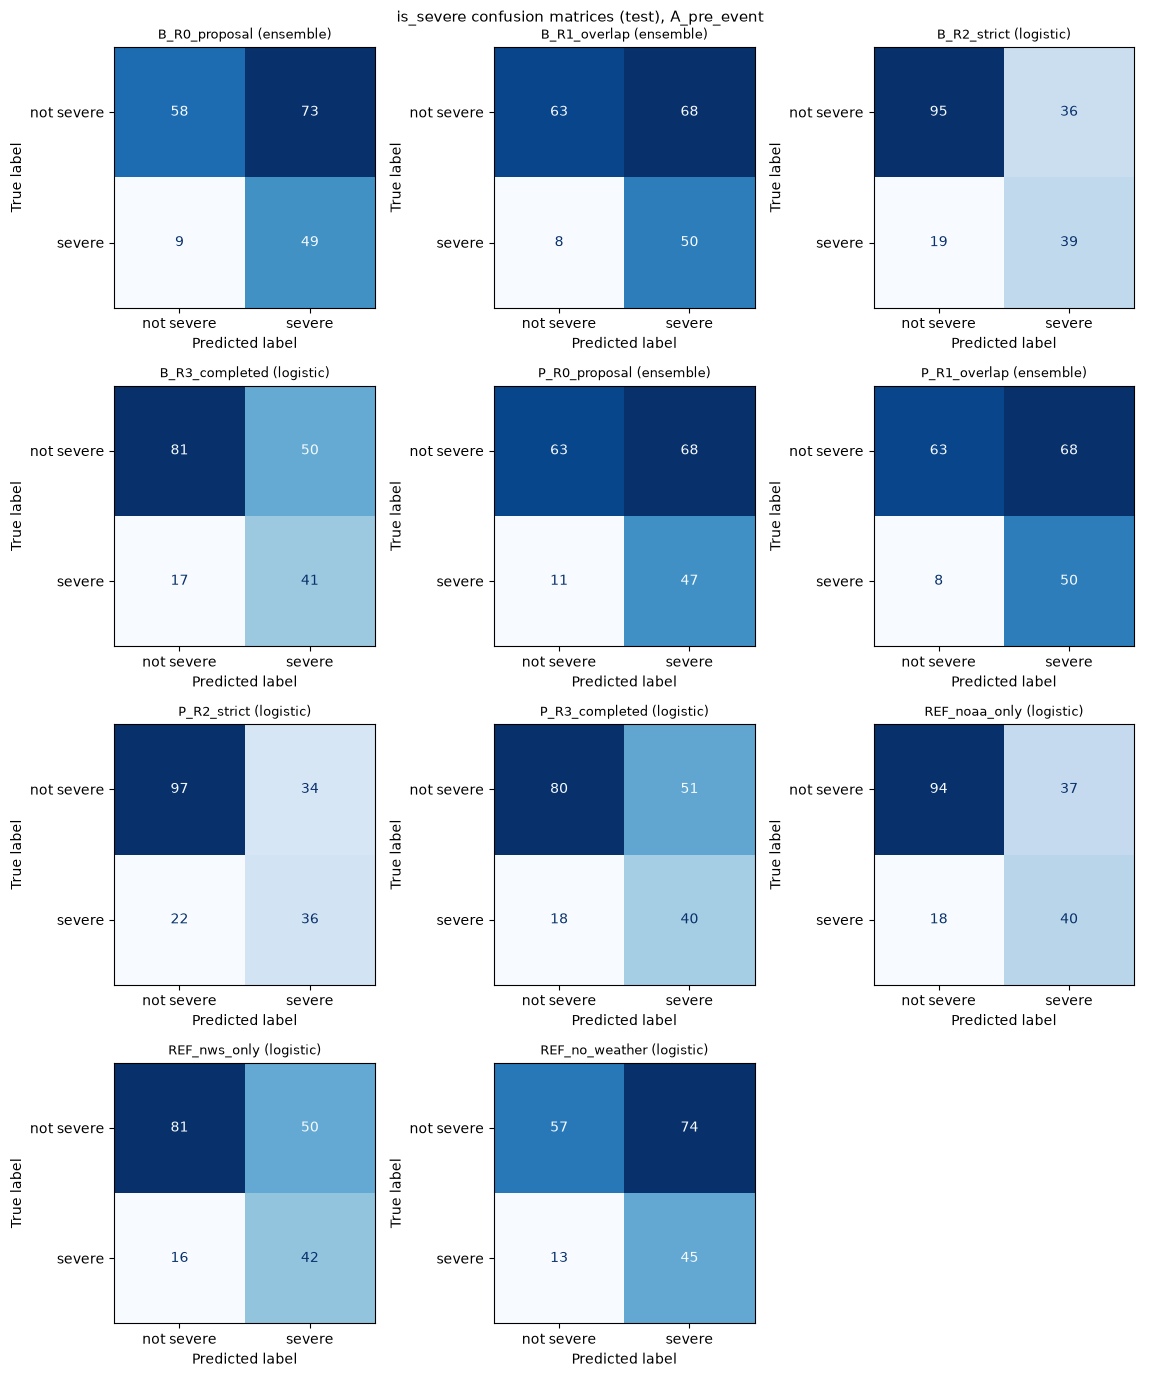

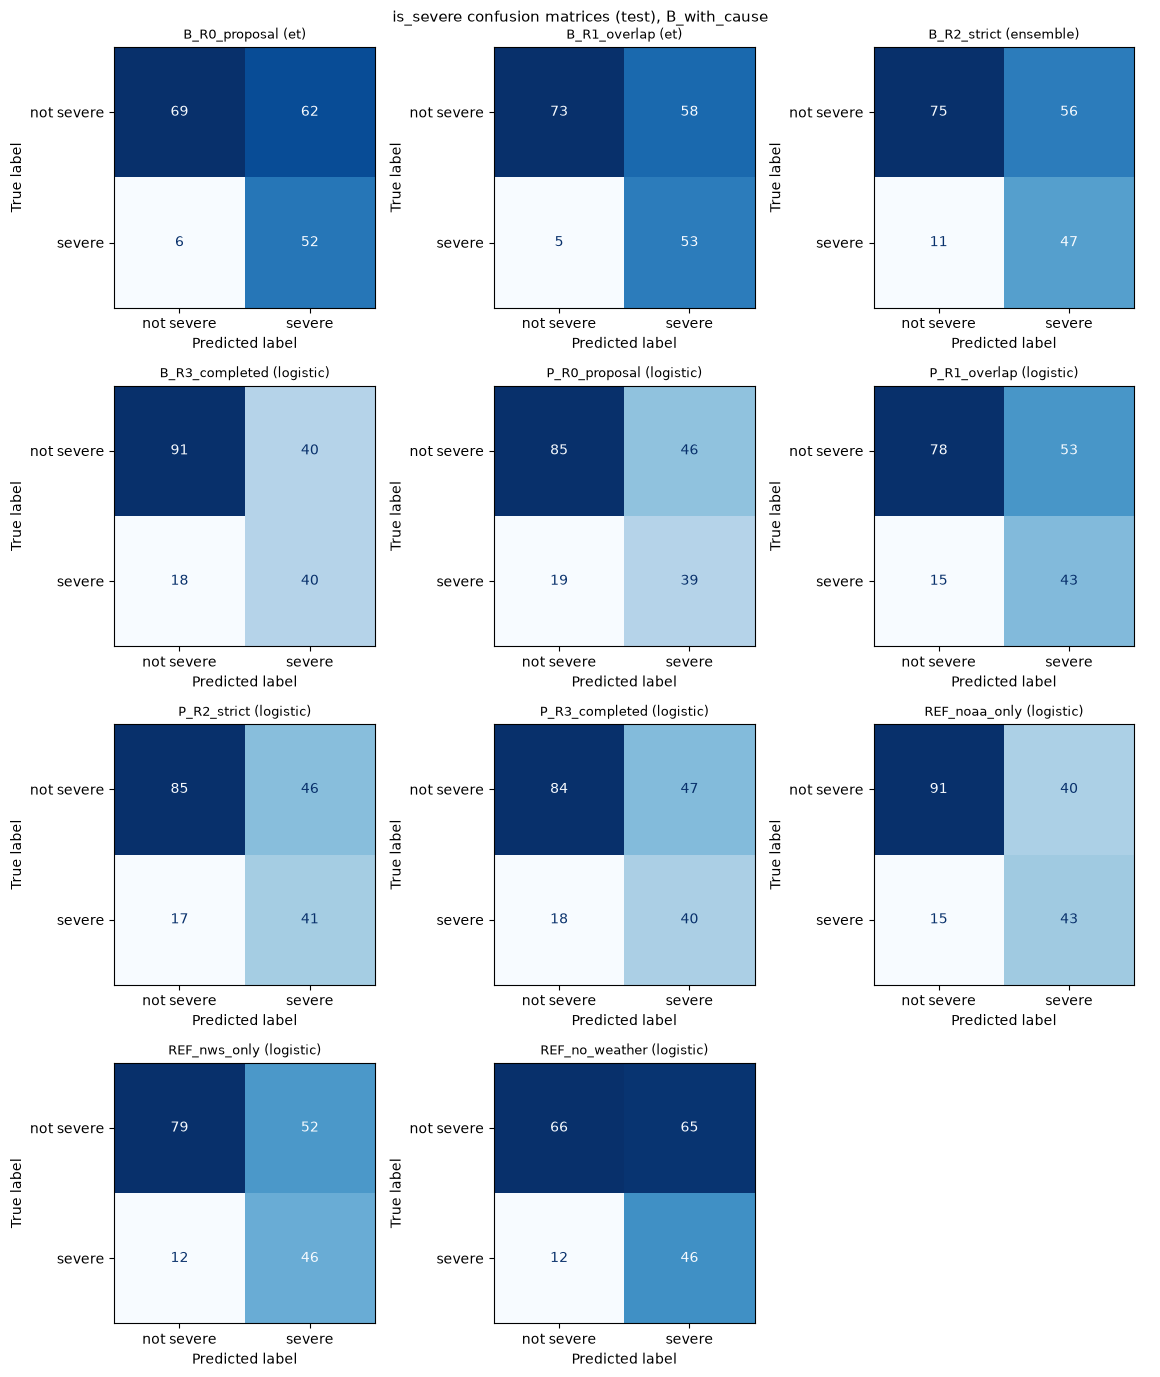

In [38]:
for scen in SCENARIOS:
    items = [
        (
            f"{run} ({m})",
            y,
            (
                p
                >= clf_results.loc[
                    (clf_results["scenario"] == scen)
                    & (clf_results["run"] == run)
                    & (clf_results["model"] == m),
                    "threshold",
                ].iloc[0]
            ).astype(int),
        )
        for (s, run, task, m), (y, p) in clf_preds.items()
        if s == scen
    ]
    plot_confusion_grid(
        items,
        f"is_severe confusion matrices (test), {scen}",
        os.path.join(OUT_DIR, f"is_severe_confusion_{scen}.png"),
        ncols=3,
    )

### base vs. proposed: does the new grid data help? (is_severe)

In [39]:
clf_cmp = base_vs_proposed(
    clf_results,
    [
        "PR_AUC_val_fold_mean",
        "PR_AUC_test",
        "ROC_AUC_test",
        "F1_test",
        "precision_test",
        "recall_test",
        "balanced_accuracy_test",
    ],
)
clf_cmp.to_csv(os.path.join(OUT_DIR, "is_severe_base_vs_proposed.csv"), index=False)
display(
    clf_cmp[
        [
            "scenario",
            "run_base",
            "model_base",
            "model_proposed",
            "PR_AUC_val_fold_mean_change",
            "PR_AUC_test_base",
            "PR_AUC_test_proposed",
            "PR_AUC_test_change",
            "ROC_AUC_test_change",
            "F1_test_change",
            "precision_test_change",
            "recall_test_change",
        ]
    ]
    .round(3)
    .reset_index(drop=True)
)

,scenario,run_base,model_base,model_proposed,PR_AUC_val_fold_mean_change,PR_AUC_test_base,PR_AUC_test_proposed,PR_AUC_test_change,ROC_AUC_test_change,F1_test_change,precision_test_change,recall_test_change
0,A_pre_event,B_R0_proposal,ensemble,ensemble,-0.003,0.585,0.592,0.008,0.004,-0.001,0.007,-0.034
1,A_pre_event,B_R1_overlap,ensemble,ensemble,-0.002,0.599,0.589,-0.009,-0.009,0.000,0.000,0.000
2,A_pre_event,B_R2_strict,logistic,logistic,-0.008,0.673,0.641,-0.032,-0.021,-0.024,-0.006,-0.052
3,A_pre_event,B_R3_completed,logistic,logistic,-0.005,0.616,0.576,-0.039,-0.035,-0.013,-0.011,-0.017
4,B_with_cause,B_R0_proposal,et,logistic,0.004,0.666,0.637,-0.029,-0.032,-0.059,0.003,-0.224
5,B_with_cause,B_R1_overlap,et,logistic,0.009,0.667,0.655,-0.011,-0.026,-0.069,-0.030,-0.172
6,B_with_cause,B_R2_strict,ensemble,logistic,0.016,0.629,0.667,0.038,0.019,-0.018,0.015,-0.103
7,B_with_cause,B_R3_completed,logistic,logistic,-0.012,0.654,0.612,-0.042,-0.022,-0.028,-0.040,0.000


## 10. Severe detection in detail (strict rule): base vs. proposed

This analysis addresses  professor's feedback "Severe-event detection performs poorly, with no useful majority-class or cost-sensitive baseline yet.". This section uses the **(strict) rule** for both models (`B_R2_strict`, `P_R2_strict`) and the **tuned model from section 9** for each.

| Group | Methods |
|---|---|
| Baselines | always not severe (majority class), always severe, random at the training rate (one draw) |
| Rules | storm active → severe; (scenario B) cause = severe weather → severe |
| Models | logistic regression (default settings); tuned model uncalibrated (0.5) and at its F1 threshold (section 9); tuned model Platt-calibrated (0.5); calibrated with a **cost-tuned threshold** (missed severe : false alarm = 1:1, 3:1, 5:1) |

- Calibration and cost thresholds are fitted on the **validation (time-based CV) predictions** of the training period only.
- Expected cost per outage = (c × missed severe + false alarms) / n; lower is better.

In [40]:
OPERATIONAL = {"base": "B_R2_strict", "proposed": "P_R2_strict"}


def _cost_threshold(p, y, c):
    grid = np.linspace(0.01, 0.99, 99)
    cost = [c * ((y == 1) & (p < t)).sum() + ((y == 0) & (p >= t)).sum() for t in grid]
    return grid[int(np.argmin(cost))]


def _logit(p):
    p = np.clip(p, 1e-4, 1 - 1e-4)
    return np.log(p / (1 - p))


def severe_detection_eval(scen, run):
    key = (scen, run, "is_severe")
    d, name = clf_data[key], clf_top[key][0]
    _, oof, fold = clf_tuned[key]
    v = fold >= 0
    y_tr, y_te, oof_v, y_v = d["y_tr"], d["y_te"], oof[name][v], d["y_tr"][v]
    raw = clf_preds[key + (name,)][1]  # tuned model refit on the whole training period
    t_f1 = clf_results.loc[
        (clf_results["scenario"] == scen)
        & (clf_results["run"] == run)
        & (clf_results["model"] == name),
        "threshold",
    ].iloc[0]
    platt = LogisticRegression(C=1e6).fit(
        _logit(oof_v)[:, None], y_v
    )  # calibration on validation predictions
    cal_v = platt.predict_proba(_logit(oof_v)[:, None])[:, 1]
    cal = platt.predict_proba(_logit(raw)[:, None])[:, 1]
    logistic = predict(fit_pipe(default_models("bin")["logistic"], d), "bin", d["X_te"])
    te_rows = tables[ALL_RUNS[run][0]].loc[d["X_te"].index]
    rng = np.random.default_rng(SEED)
    m = {
        "baseline: always not severe": (np.zeros(len(y_te), int), None),
        "baseline: always severe": (np.ones(len(y_te), int), None),
        "baseline: random (one draw)": (
            (rng.random(len(y_te)) < y_tr.mean()).astype(int),
            None,
        ),
        "rule: storm active": (
            (te_rows["noaa_has_storm"].values == 1).astype(int),
            None,
        ),
    }
    if "cause_reported" in d["cat"]:
        m["rule: cause = severe weather"] = (
            (te_rows["cause_reported"].values == "severe weather").astype(int),
            None,
        )
    m["logistic regression (0.5)"] = ((logistic >= 0.5).astype(int), logistic)
    m[f"{name}, uncalibrated (0.5)"] = ((raw >= 0.5).astype(int), raw)
    m[f"{name}, F1 threshold (t={t_f1:.2f})"] = ((raw >= t_f1).astype(int), raw)
    m[f"{name}, calibrated (0.5)"] = ((cal >= 0.5).astype(int), cal)
    for c in COST_RATIOS:
        t = _cost_threshold(cal_v, y_v, c)
        m[f"{name}, cost {c}:1 (t={t:.2f})"] = ((cal >= t).astype(int), cal)
    rows = []
    for method, (yhat, p) in m.items():
        cost = {
            f"cost_{c}to1": (
                c * ((y_te == 1) & (yhat == 0)).sum()
                + ((y_te == 0) & (yhat == 1)).sum()
            )
            / len(y_te)
            for c in COST_RATIOS
        }
        rows.append(
            {
                "scenario": scen,
                "method": method,
                **classification_metrics(y_te, yhat, p),
                **cost,
            }
        )
    bins = np.clip((cal * 10).astype(int), 0, 9)
    rel = (
        pd.DataFrame(
            {"bin": bins, "pred_calibrated": cal, "pred_raw": raw, "observed": y_te}
        )
        .groupby("bin")
        .agg(
            mean_pred_calibrated=("pred_calibrated", "mean"),
            mean_pred_raw=("pred_raw", "mean"),
            observed_rate=("observed", "mean"),
        )
        .reset_index()
    )
    info_ = {
        "scenario": scen,
        "tuned_model": name,
        "n_test": len(y_te),
        "test_severe_rate": y_te.mean(),
        "train_severe_rate": y_tr.mean(),
    }
    return pd.DataFrame(rows), y_te, m, rel, info_


sev_tables, sev_preds, sev_rel, sev_info = [], {}, {}, []
for model_name, run in OPERATIONAL.items():
    if run not in ALL_RUNS:
        continue
    for scen in SCENARIOS:
        t, y_te, m, rel_, inf = severe_detection_eval(scen, run)
        sev_tables.append(t.assign(model=model_name, run=run))
        sev_preds[(model_name, scen)] = (y_te, m)
        sev_rel[(model_name, scen)] = rel_
        sev_info.append({"model": model_name, "run": run, **inf})
sev = pd.concat(sev_tables, ignore_index=True)
sev.to_csv(os.path.join(OUT_DIR, "severe_detection.csv"), index=False)
display(pd.DataFrame(sev_info).round(3))
display(
    sev[
        [
            "model",
            "scenario",
            "method",
            "precision",
            "recall",
            "F1",
            "ROC_AUC",
            "PR_AUC",
            "balanced_accuracy",
            "accuracy",
            "cost_3to1",
            "cost_5to1",
        ]
    ].round(3)
)

,model,run,scenario,tuned_model,n_test,test_severe_rate,train_severe_rate
0,base,B_R2_strict,A_pre_event,logistic,189,0.307,0.5
1,base,B_R2_strict,B_with_cause,ensemble,189,0.307,0.5
2,proposed,P_R2_strict,A_pre_event,logistic,189,0.307,0.5
3,proposed,P_R2_strict,B_with_cause,logistic,189,0.307,0.5


,model,scenario,method,precision,recall,F1,ROC_AUC,PR_AUC,balanced_accuracy,accuracy,cost_3to1,cost_5to1
0,base,A_pre_event,baseline: always not severe,0.000,0.000,0.000,NaN,NaN,0.500,0.693,0.921,1.534
1,base,A_pre_event,baseline: always severe,0.307,1.000,0.470,NaN,NaN,0.500,0.307,0.693,0.693
2,base,A_pre_event,baseline: random (one draw),0.381,0.638,0.477,NaN,NaN,0.590,0.571,0.651,0.873
3,base,A_pre_event,rule: storm active,0.318,0.862,0.465,NaN,NaN,0.523,0.392,0.693,0.778
4,base,A_pre_event,logistic regression (0.5),0.579,0.569,0.574,0.772,0.687,0.693,0.741,0.524,0.788
5,base,A_pre_event,"logistic, uncalibrated (0.5)",0.630,0.500,0.558,0.760,0.673,0.685,0.757,0.550,0.857
6,base,A_pre_event,"logistic, F1 threshold (t=0.40)",0.520,0.672,0.586,0.760,0.673,0.699,0.709,0.492,0.693
7,base,A_pre_event,"logistic, calibrated (0.5)",0.674,0.500,0.574,0.760,0.673,0.697,0.772,0.534,0.841
8,base,A_pre_event,"logistic, cost 1:1 (t=0.47)",0.600,0.517,0.556,0.760,0.673,0.682,0.746,0.550,0.847
9,base,A_pre_event,"logistic, cost 3:1 (t=0.17)",0.379,0.948,0.542,0.760,0.673,0.631,0.508,0.524,0.556


### Confusion matrices: severe detection

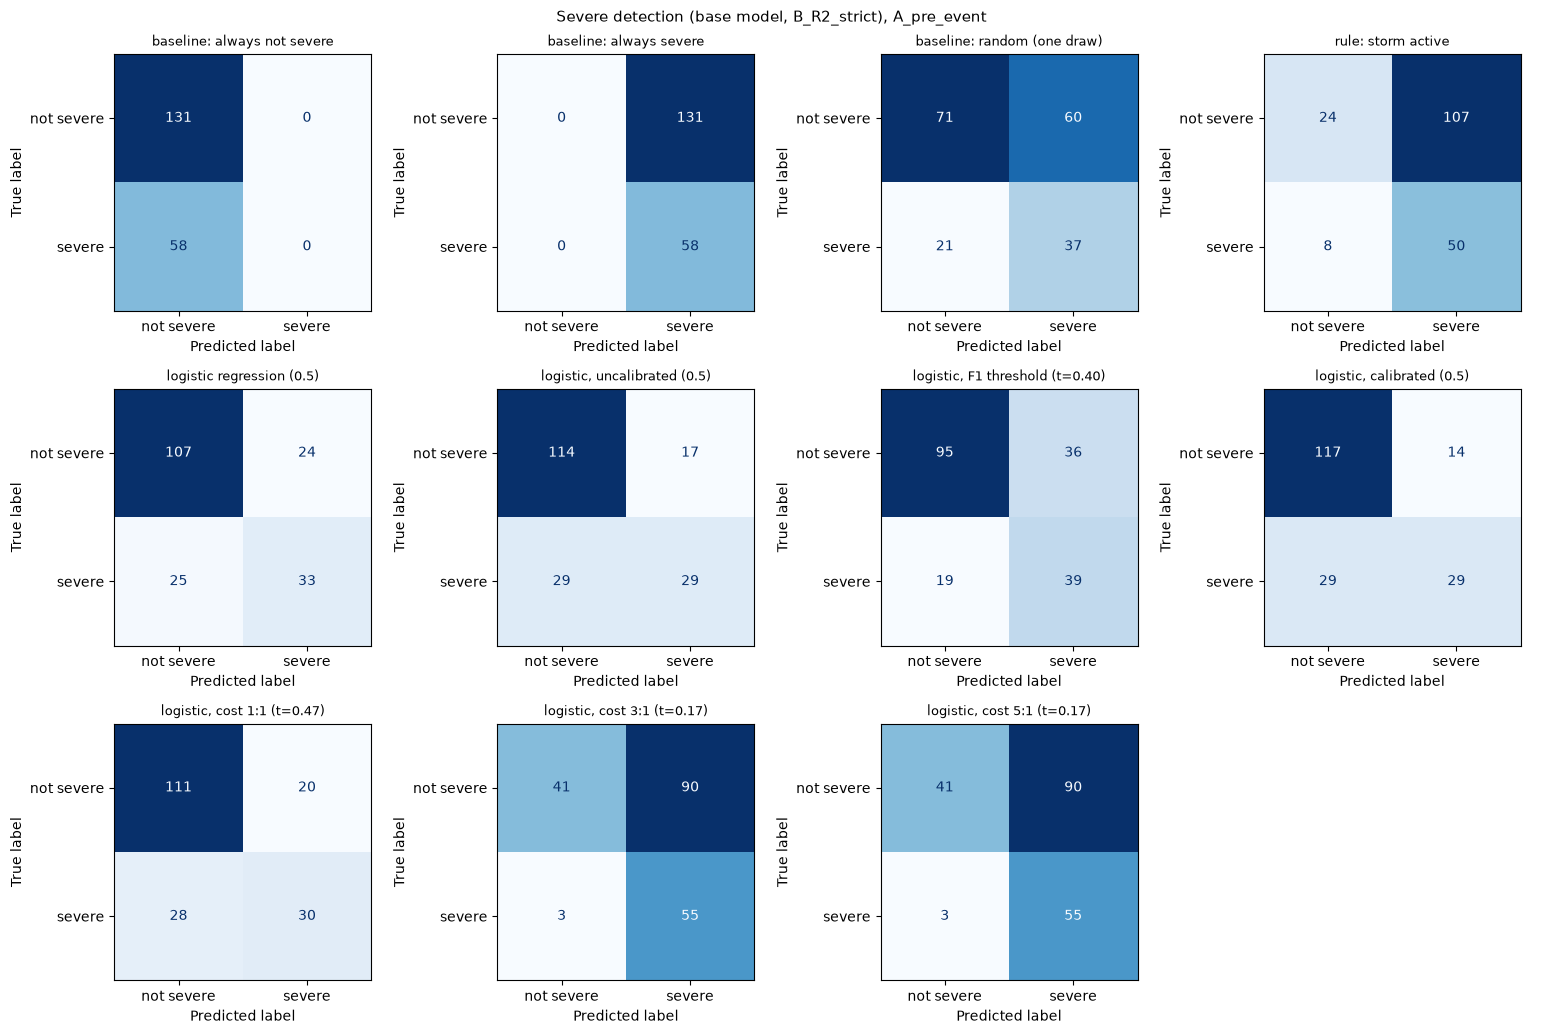

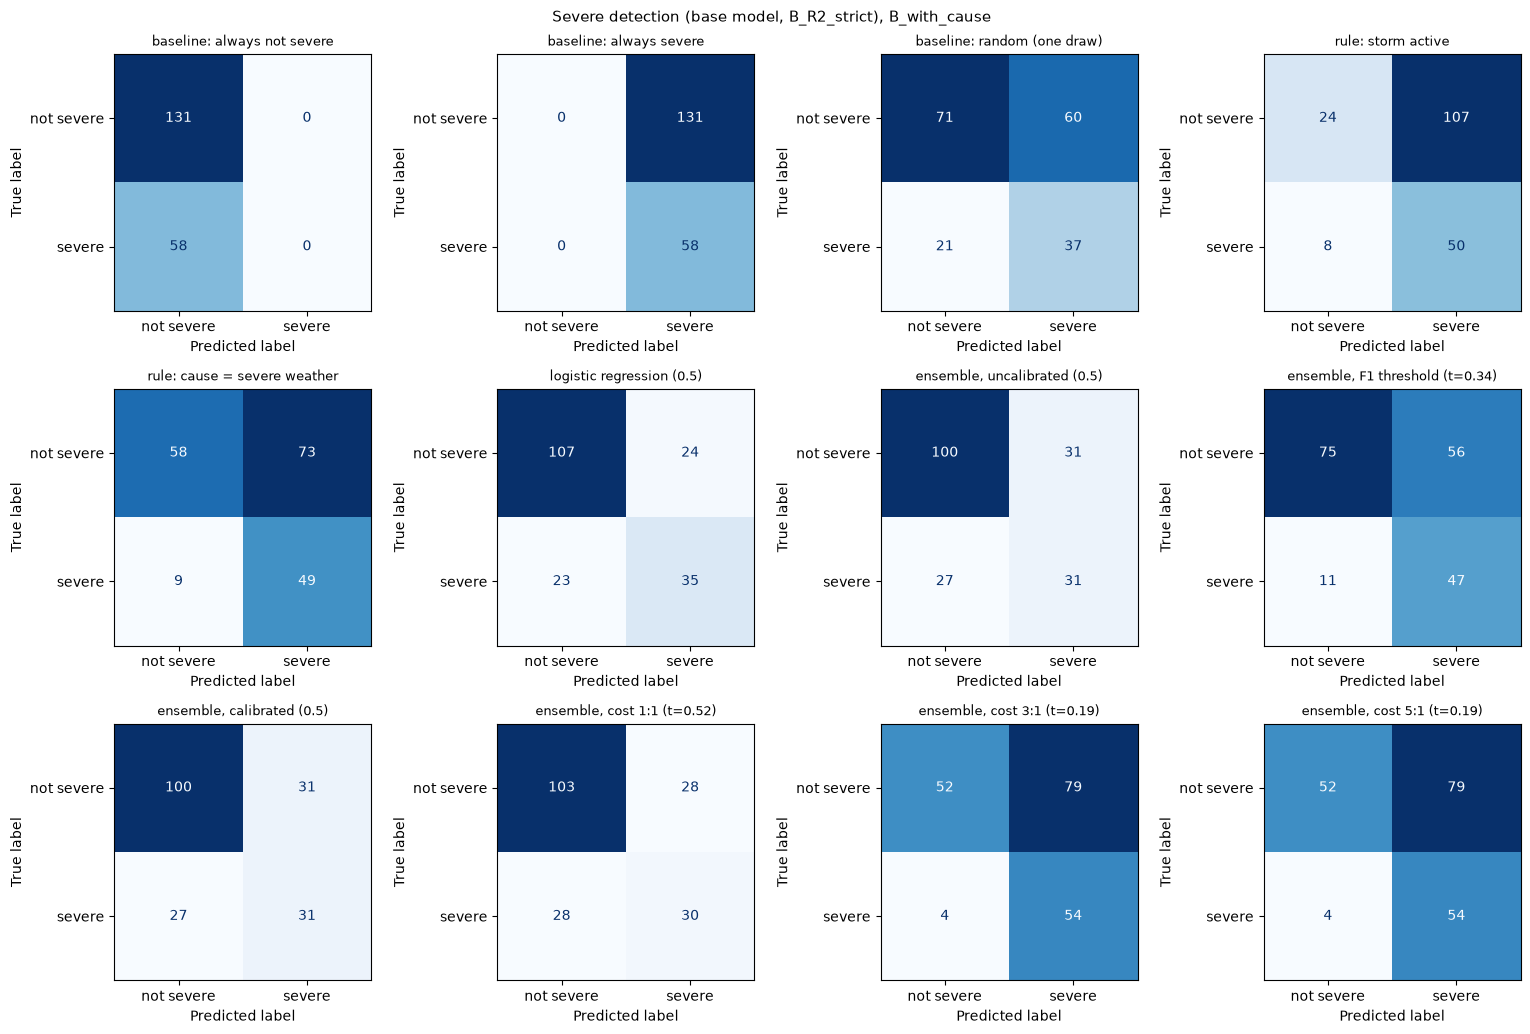

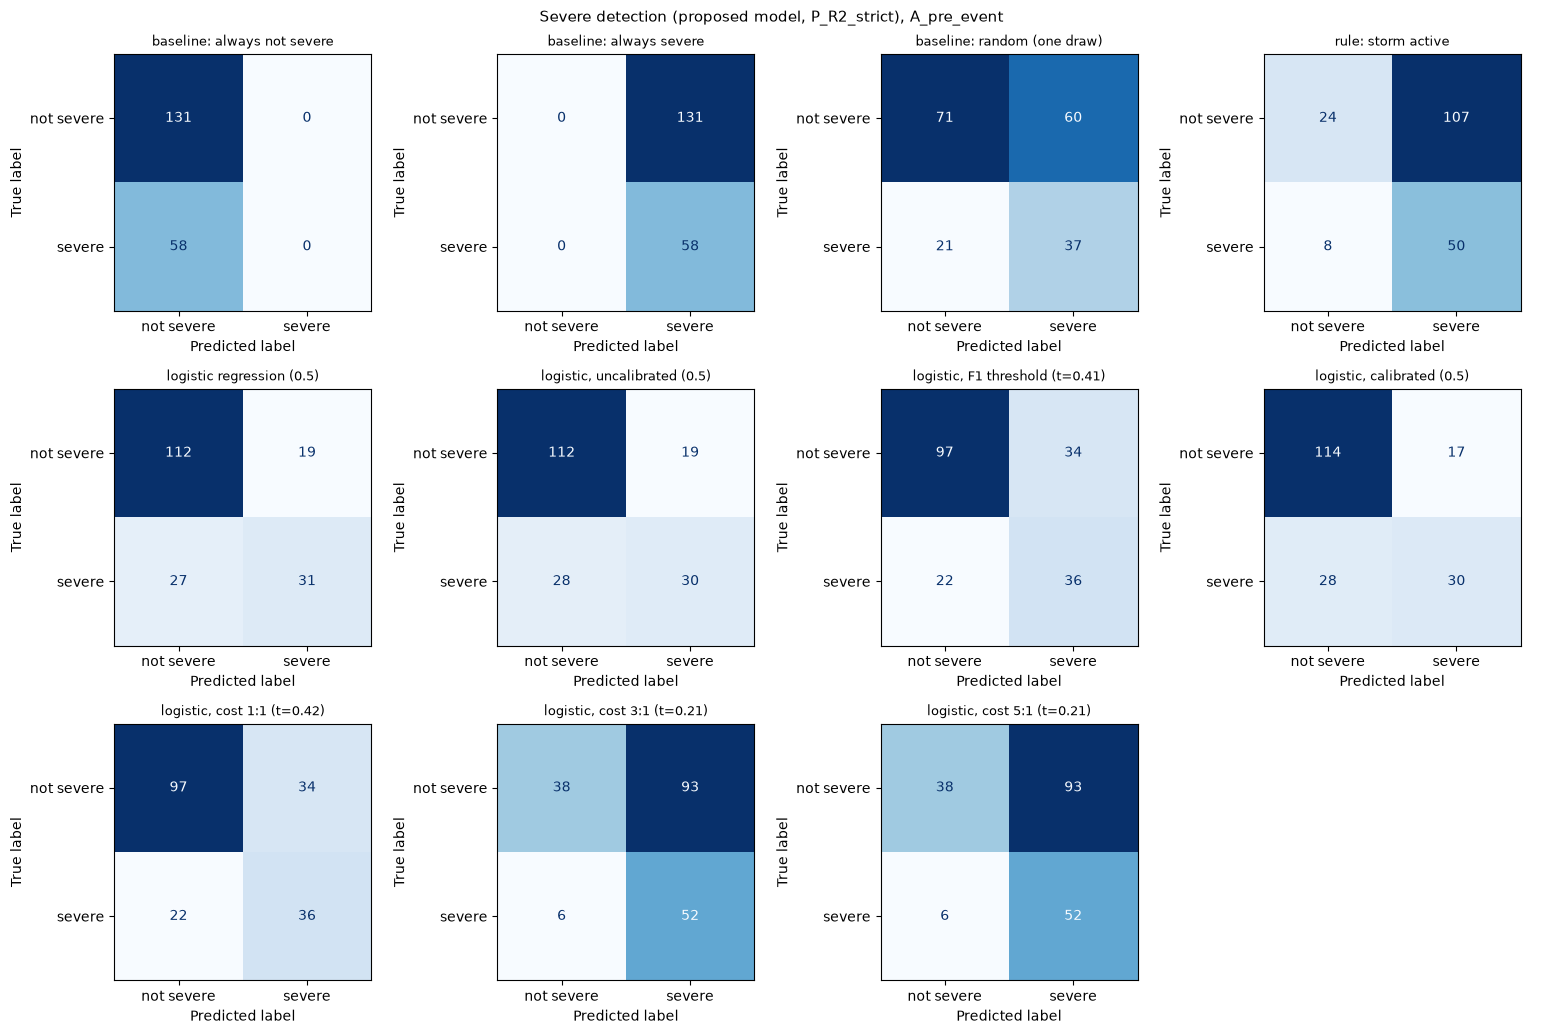

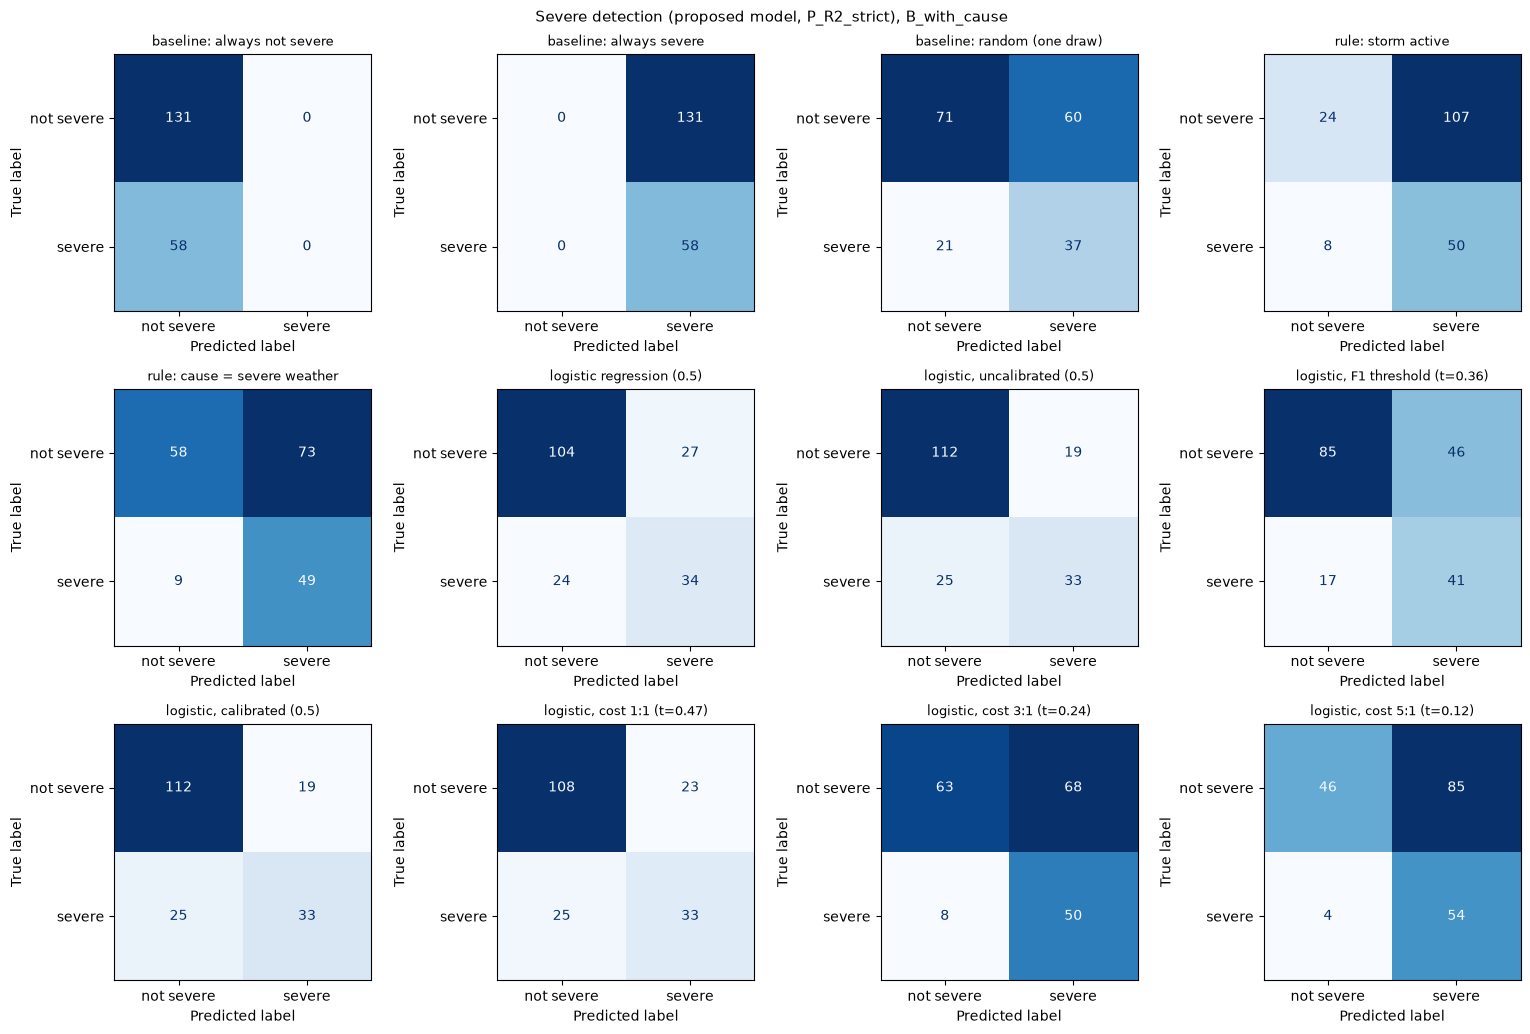

In [41]:
for (model_name, scen), (y_te, m) in sev_preds.items():
    items = [(name, y_te, yhat) for name, (yhat, p) in m.items()]
    plot_confusion_grid(
        items,
        f"Severe detection ({model_name} model, {OPERATIONAL[model_name]}), {scen}",
        os.path.join(OUT_DIR, f"severe_confusion_{model_name}_{scen}.png"),
        ncols=4,
    )

### Reliability (calibration) plot

When the model says "x% chance of severe", how often was it really severe? Points on the dashed line are honest probabilities.

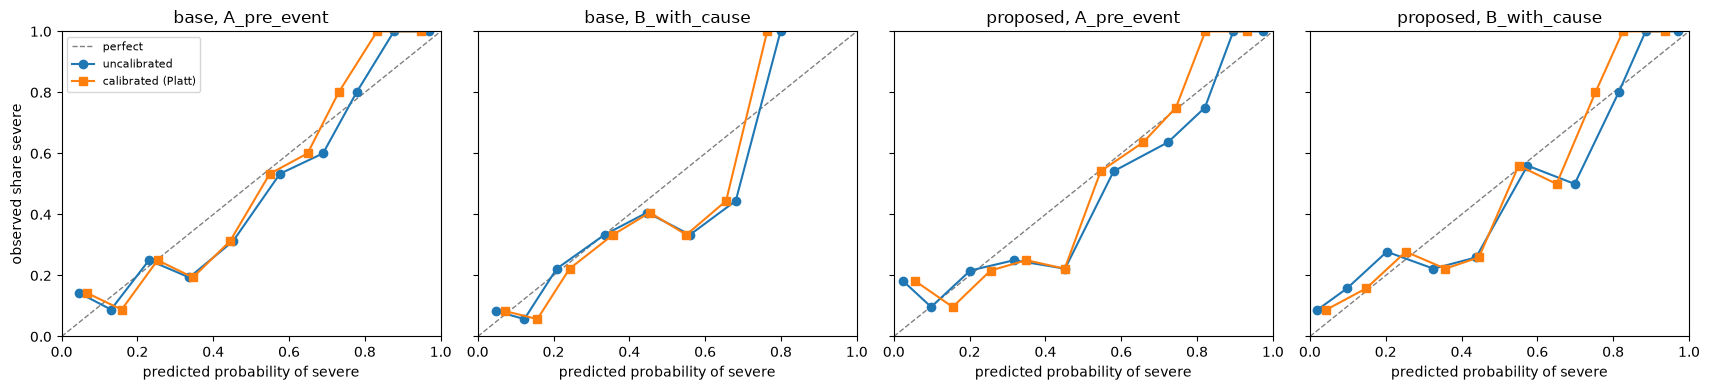

In [42]:
fig, axes = plt.subplots(1, len(sev_rel), figsize=(4.3 * len(sev_rel), 4), sharey=True)
axes = np.atleast_1d(axes)
for ax, ((model_name, scen), g) in zip(axes, sev_rel.items()):
    ax.plot([0, 1], [0, 1], ls="--", c="grey", lw=1, label="perfect")
    ax.plot(g["mean_pred_raw"], g["observed_rate"], "o-", label="uncalibrated")
    ax.plot(
        g["mean_pred_calibrated"], g["observed_rate"], "s-", label="calibrated (Platt)"
    )
    ax.set(
        title=f"{model_name}, {scen}",
        xlabel="predicted probability of severe",
        xlim=(0, 1),
        ylim=(0, 1),
    )
axes[0].set_ylabel("observed share severe")
axes[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "reliability.png"), dpi=130)
plt.show()

## 11. Summary

The results are in the tables above and in `progress_stage2/results_outage_extended_noaa_nws_newgrid/` (`regression_*.csv`, `is_severe_*.csv`; test period 2022–2024).
- **Sections 8.1 / 9.1** show which model wins the default-settings CV for each run.
- **Sections 8.2 / 9.2** show what the grid search changes.
- **Sections 8.3 / 9.3** give train, validation and test scores per run: comparing runs compares the storm rules. The references show what NWS warnings add (`REF_noaa_only`) and how well real-time warnings do on their own (`REF_nws_only`, the most defensible weather input for the operational claim, W1).
- **Sections 8.4 / 9.5** show what the new grid data (EIA-861 / FERC Form 1) changes for each storm rule.
- **Section 10** compares severe-detection methods for the operational rule, including baselines and cost-sensitive thresholds (feedback W3).

Notes for interpretation:
- NWS features are missing for outages before 2006 (the archive is complete only from Nov 2005); the test period 2022–2024 is fully covered.
- Compare differences between runs with the validation spread (`_val_std`): changes of a few hundredths can be noise.
- Each run picks its own model, so a difference between runs can come from the data **and** from the model choice; the `model` columns show when they differ.